# From Words to Worlds — Combined Milestone 1 Experiment

**Tanmayi Shurpali** · IE 7615 Deep Learning for AI · Northeastern University

This notebook combines the group's four Milestone 1 runs into one pipeline and adds some pieces as well. Every component says where it came from.

| Part | Source | Status in this notebook |
|---|---|---|
| COCO val2017 data, light caption cleaning, 512×512 PNG, frozen `eval_2000` / `eval_500` (seed 2026) | **Santhosh** (same method as Praniti) | rebuilt, then checked against the group's frozen files |
| `dev_500` tuning split, `real_ref_b_2000` FID reference, data checks, object labels with crop check, 200 stress prompts, split-word table | **Praniti** | rebuilt with her code, checked against her files |
| Text → embedding (one caption at a time, no mask), cache, pixel-exact parity with SD | **Santhosh + Praniti** | rebuilt and re-verified |
| Attention recorder and commit step | **Santhosh** | adapted (word pieces joined using Praniti's split-word rule) |
| LoRA fine-tuning of the UNet (rank 8, 0.185%) | **Mukul** | his trained checkpoints reused; retraining code included as a fallback |
| Text-encoder comparison (CLIP, BERT, T5, GPT-2, TF-IDF) | **Praniti** | rerun, with my additions below |
| Rewind tool, steering / editing / moment-of-loss pilots, connector runs | **Santhosh, Mukul** | reported in §13, not rerun (GPU budget) |

**What I add (my contributions):**
1. **Image-quality scores**: FID, KID and Inception Score, each next to the score real photos get against the same reference at the same sample size. This was the project's biggest gap.
2. **Two image judges for missing objects**: a Faster R-CNN detector and an open-vocabulary OWL-ViT detector. Praniti's labels say *which* objects each image must contain, and an object counts as missing only when **both** judges miss it. Both judges are first **calibrated on the real photos**, so their own miss rate is known.
3. **A fair LoRA evaluation**: Mukul's checkpoint is chosen on `dev_500` (not on the prompts it is scored on), then scored on the frozen `eval_500` with the group's sampler (PNDM, 30 steps, guidance 7.5) and paired bootstrap intervals, plus a 3-seed check.
4. **Headline experiment — does fine-tuning change *when* the model commits to each word?** Santhosh's commit step is measured on the same captions before and after LoRA, and I test whether a late commit predicts that the object goes missing.
5. **Stress prompts** (Praniti's multi-object and counting sets) scored for base vs LoRA.
6. **Encoder comparison with error bars** and a corrected word-order / colour test (the original test was confounded by sentence structure, as Praniti noted).
7. **Retrieval at both pool sizes** (2,000 and 5,000 photos), so the team's two numbers can finally be compared directly.

### How to run (free Colab T4)
1. *Runtime → Change runtime type → T4 GPU*.
2. In Google Drive, create the folder **`MyDrive/w2w_tanmayi/inputs/`** and upload **Mukul's `project_2.zip`** there (it holds the LoRA checkpoints). Optional: also upload **Praniti's results zip**; if it is there, her sample images are used for a cross-run pixel check.
3. *Runtime → Run all*. Every generated image is saved to Drive as it is made, so if Colab disconnects, just **Run all again** and it continues where it stopped.

| Stage | Approx. time on a T4 |
|---|---|
| Install, download COCO val2017, preprocess, splits, labels | ~10 min |
| Embeddings and retrieval (2,000 and 5,000 photos) | ~6 min |
| Checkpoint selection on 80 dev captions (base + 4 checkpoints) | ~35 min |
| Base vs LoRA on `eval_500` | ~90 min |
| 3-seed check (100 captions × 2 more seeds × 2 models) | ~35 min |
| Judges, FID/KID/IS, stress prompts (80 × 2), word timing (60 × 2) | ~40 min |
| Encoder comparison | ~5 min |

**Total ≈ 3.5–4 h.** It can be split over several sessions. To make it faster, lower `n_eval`, `seed_check_n` or `n_dev_select` in the config cell.

## 1. Install
Versions pinned to the ones Praniti's run used successfully on a Colab T4 (Diffusers 0.42.1, Transformers 5.22.1). Colab's preinstalled `torchao` clashes with PEFT, so it is removed first (as in Mukul's notebook). If an import fails right after installing, use *Runtime → Restart session* and *Run all* again.

In [1]:
%pip uninstall -y -q torchao
%pip install -q diffusers==0.42.1 transformers==5.22.1 accelerate safetensors peft ftfy sentencepiece scikit-learn torch-fidelity clean-fid

## 2. Setup and configuration
One config object holds every setting. The data and sampling settings are the group's agreed ones. The budget settings (bottom block) are the only things to change for a shorter run.

In [2]:
import os, sys, re, io, json, math, time, random, shutil, zipfile, hashlib, platform, textwrap, warnings
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from dataclasses import dataclass, asdict, field
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from PIL import Image, ImageDraw, ImageOps
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
NOTEBOOK_START = time.time()


@dataclass
class Config:
    # ---- data: Santhosh + Praniti, unchanged ----
    seed_eval: int = 2026
    seed_dev: int = 2027
    seed_ref: int = 2028
    seed_stress: int = 2030
    image_size: int = 512
    min_short_side: int = 256
    n_eval_split: int = 2000
    n_dev: int = 500
    n_ref_b: int = 2000
    min_box_kept: float = 0.5
    min_cover: float = 0.005
    # ---- models ----
    clip_id: str = "openai/clip-vit-large-patch14"
    sd_id: str = "stable-diffusion-v1-5/stable-diffusion-v1-5"
    # ---- sampling: the group's agreed setting for every comparison ----
    steps: int = 30
    guidance: float = 7.5
    main_seed: int = 0
    # ---- judges ----
    det_score: float = 0.5                      # Faster R-CNN score threshold (as in Santhosh's pilots)
    owl_id: str = "google/owlvit-base-patch32"
    owl_threshold: float = 0.1
    # ---- word timing (Santhosh's definition) ----
    commit_threshold: float = 0.8
    commit_thresholds_sweep: tuple = (0.7, 0.8, 0.9)
    # ---- LoRA (Mukul) ----
    lora_checkpoints: tuple = (150, 300, 450, 600)
    retrain_lora_if_missing: bool = True        # only used if Mukul's checkpoints are not found
    # ---- statistics ----
    n_boot: int = 5000
    # ---- budget knobs: lower these for a shorter run ----
    n_eval: int = 500                           # eval_500 = first 500 rows of eval_2000
    n_dev_select: int = 80                      # dev_500 captions used to choose the LoRA checkpoint
    seed_check_n: int = 100                     # captions in the 3-seed check
    seed_check_seeds: tuple = (1, 2)            # extra seeds on top of main_seed
    n_timing: int = 60                          # captions in the word-timing experiment
    stress_families: tuple = ("multi_object", "counting")
    run_encoder_comparison: bool = True


CFG = Config()

# The group's frozen files, fingerprinted from Praniti's results (identical to Santhosh's by his comparison doc).
EXPECTED_DIGESTS = {
    "eval_2000": "e14b335b5ee2a496", "eval_500": "71a327816f95c94e", "dev_500": "bb62dd505c9d161f",
    "real_ref_b_2000": "949ef2a5c65f18fd", "groundtruth_eval_2000": "eb23d9d9f78ef622", "stress_prompts": "ba9373474debf155",
}

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    LOCAL = Path("/content/w2w_local")                        # big, re-downloadable data (fast local disk)
    OUT = Path("/content/drive/MyDrive/w2w_tanmayi")          # results and generated images (survive disconnects)
else:
    LOCAL = Path.cwd() / "w2w_local"
    OUT = Path.cwd() / "w2w_tanmayi"

COCO = LOCAL / "coco"
IMAGES_DIR = COCO / "val2017"
ANN_DIR = COCO / "annotations"
CAP_JSON, INST_JSON = ANN_DIR / "captions_val2017.json", ANN_DIR / "instances_val2017.json"
PROC_DIR = COCO / "val2017_512"
CACHE = LOCAL / "cache"
INPUTS = OUT / "inputs"
RES_DIR = OUT / "results"
FIGS = RES_DIR / "figures"
SPLITS = RES_DIR / "splits"
GEN = OUT / "generated"
for p in (COCO, PROC_DIR, CACHE, INPUTS, RES_DIR, FIGS, SPLITS, GEN):
    p.mkdir(parents=True, exist_ok=True)
json.dump(asdict(CFG), open(RES_DIR / "config.json", "w"), indent=2)


def to_py(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    if isinstance(o, np.ndarray): return o.tolist()
    if isinstance(o, Path): return str(o)
    return str(o)


RESULTS_JSON = RES_DIR / "results.json"
RES = json.load(open(RESULTS_JSON)) if RESULTS_JSON.exists() else {}


def _clean(o):
    if isinstance(o, dict): return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_clean(v) for v in o]
    if isinstance(o, (float, np.floating)) and not np.isfinite(o): return None
    return o


def record(key, value):
    # every headline number goes into results.json the moment it is computed (NaN written as null)
    RES[key] = _clean(json.loads(json.dumps(value, default=to_py)))
    json.dump(RES, open(RESULTS_JSON, "w"), indent=2)


def savefig(name):
    plt.savefig(FIGS / f"{name}.png", bbox_inches="tight", dpi=140)


def seed_everything(s):
    random.seed(s); np.random.seed(s)
    try:
        import torch; torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    except ImportError:
        pass


seed_everything(0)
print("local data :", LOCAL)
print("results    :", OUT)
print("inputs     :", INPUTS, "->", sorted(p.name for p in INPUTS.iterdir()) or "EMPTY (upload Mukul's project_2.zip here)")

Mounted at /content/drive
local data : /content/w2w_local
results    : /content/drive/MyDrive/w2w_tanmayi
inputs     : /content/drive/MyDrive/w2w_tanmayi/inputs -> ['mukul', 'project 2.zip', 'results']


## 3. Data: COCO val2017 *(Santhosh + Praniti)*
Both of them use the full 5,000-image validation split with light cleaning: whitespace and spacing before punctuation are repaired, and exact duplicates within an image are dropped. **Wording is never changed**, because test prompts should stay as people wrote them. This is Praniti's code, which implements Santhosh's design.

In [3]:
IMAGES_URL = "http://images.cocodataset.org/zips/val2017.zip"
ANN_URL = "http://images.cocodataset.org/annotations/annotations_trainval2017.zip"


def download(url, dest):
    if dest.exists() and dest.stat().st_size > 0:
        return dest
    tmp = dest.with_suffix(dest.suffix + ".part")
    with requests.get(url, stream=True, timeout=60) as r:
        r.raise_for_status()
        total = int(r.headers.get("content-length", 0))
        with open(tmp, "wb") as f, tqdm(total=total, unit="B", unit_scale=True, desc=dest.name) as bar:
            for chunk in r.iter_content(chunk_size=1 << 20):
                f.write(chunk); bar.update(len(chunk))
    tmp.rename(dest)
    return dest


if not (IMAGES_DIR.exists() and len(list(IMAGES_DIR.glob("*.jpg"))) == 5000):     # a half-finished unzip is redone
    with zipfile.ZipFile(download(IMAGES_URL, COCO / "val2017.zip")) as z:
        z.extractall(COCO)
ANN_ZIP = download(ANN_URL, COCO / "annotations_trainval2017.zip")     # kept: the LoRA fallback also needs train captions
if not (CAP_JSON.exists() and INST_JSON.exists()):
    with zipfile.ZipFile(ANN_ZIP) as z:
        z.extractall(COCO, [m for m in z.namelist() if m.endswith(("captions_val2017.json", "instances_val2017.json"))])

caps_json = json.load(open(CAP_JSON, encoding="utf-8"))
inst_json = json.load(open(INST_JSON, encoding="utf-8"))
print(f"{len(caps_json['images']):,} images, {len(caps_json['annotations']):,} captions, "
      f"{len(inst_json['annotations']):,} object boxes in {len(inst_json['categories'])} categories")

val2017.zip:   0%|          | 0.00/816M [00:00<?, ?B/s]

annotations_trainval2017.zip:   0%|          | 0.00/253M [00:00<?, ?B/s]

5,000 images, 25,014 captions, 36,781 object boxes in 80 categories


In [4]:
_WS = re.compile(r"\s+")


def clean_caption(text):
    t = _WS.sub(" ", text.replace("\n", " ")).strip()
    return re.sub(r"\s+([.,!?;:])", r"\1", t)


assert clean_caption("A man  riding\na wave .") == "A man riding a wave."
assert clean_caption("A plate of food with brocolli.") == "A plate of food with brocolli."   # spelling kept


def build_manifest(caps_json, inst_json):
    cat_name = {c["id"]: c["name"] for c in inst_json["categories"]}
    captions_by_image, cats_by_image = {}, {}
    for a in caps_json["annotations"]:
        captions_by_image.setdefault(a["image_id"], []).append(a["caption"])
    for a in inst_json["annotations"]:
        cats_by_image.setdefault(a["image_id"], set()).add(cat_name[a["category_id"]])
    log, rows = Counter(), []
    for im in caps_json["images"]:
        raw = captions_by_image.get(im["id"], [])
        cleaned, seen = [], set()
        for c in raw:
            cc = clean_caption(c)
            if cc != c:
                log["captions_whitespace_fixed"] += 1
            if not cc:
                log["captions_empty_dropped"] += 1; continue
            if cc.lower() in seen:
                log["captions_duplicate_dropped"] += 1; continue
            seen.add(cc.lower()); cleaned.append(cc)
        rows.append({"image_id": im["id"], "file_name": im["file_name"], "width": im["width"], "height": im["height"],
                     "n_captions_raw": len(raw), "captions": cleaned, "n_captions": len(cleaned),
                     "categories": sorted(cats_by_image.get(im["id"], set()))})
    df = pd.DataFrame(rows).sort_values("image_id").reset_index(drop=True)
    log["images"] = len(df); log["captions_raw"] = int(df.n_captions_raw.sum()); log["captions_kept"] = int(df.n_captions.sum())
    return df, dict(log)


def caption_table(df):
    out = df.explode("captions").rename(columns={"captions": "caption"}).dropna(subset=["caption"])
    out = out[["image_id", "file_name", "caption"]].reset_index(drop=True)
    out.insert(0, "caption_idx", range(len(out)))
    return out


manifest, cleaning_log = build_manifest(caps_json, inst_json)
caps = caption_table(manifest)
caps.to_csv(RES_DIR / "captions.csv", index=False)
names = dict(zip(manifest.image_id, manifest.file_name))
print(json.dumps(cleaning_log, indent=2))
assert cleaning_log["captions_kept"] == 25004, "caption count differs from the group's 25,004"
record("data", {"cleaning": cleaning_log})

{
  "captions_whitespace_fixed": 3832,
  "captions_duplicate_dropped": 10,
  "images": 5000,
  "captions_raw": 25014,
  "captions_kept": 25004
}


In [5]:
ORIENTATION_TAG = 274


def center_square(img, size):
    w, h = img.size
    s = min(w, h)
    left, top = (w - s) // 2, (h - s) // 2
    return img.crop((left, top, left + s, top + s)).resize((size, size), Image.LANCZOS)


def dhash_bits(img, size=16):
    g = np.asarray(img.convert("L").resize((size + 1, size), Image.BILINEAR), dtype=np.int16)
    return (g[:, 1:] > g[:, :-1]).flatten()


def png_path(file_name):
    return PROC_DIR / (Path(file_name).stem + ".png")


def process_one(r):
    out = png_path(r.file_name)
    with Image.open(IMAGES_DIR / r.file_name) as im:
        mode, (w, h) = im.mode, im.size
        try:
            orient = int(im.getexif().get(ORIENTATION_TAG, 1))
        except Exception:
            orient = 1
        rgb = im.convert("RGB")
    bits = dhash_bits(rgb)
    if not out.exists():
        tmp = out.with_name(out.stem + ".tmp.png")
        center_square(rgb, CFG.image_size).save(tmp)
        tmp.replace(out)
    s = min(w, h)
    return {"image_id": r.image_id, "file_512": out.name, "mode_in": mode, "w": w, "h": h, "exif_orientation": orient,
            "crop_fraction_kept": round(s * s / (w * h), 4), "reference_eligible": s >= CFG.min_short_side,
            "hash": np.packbits(bits)}


with ThreadPoolExecutor(max_workers=8) as pool:
    results = list(tqdm(pool.map(process_one, manifest.itertuples()), total=len(manifest), desc="512 x 512 PNG"))
pre = pd.DataFrame(results)
HASHES = np.stack([np.unpackbits(h) for h in pre.pop("hash")]).astype(bool)
pre.to_csv(RES_DIR / "preprocess_log.csv", index=False)


def near_duplicate_pairs(hashes, max_hamming=12):
    b = hashes.astype(np.float32) * 2 - 1
    dist = (b.shape[1] - b @ b.T) / 2
    i, j = np.where(np.triu(dist <= max_hamming, k=1))
    return [(int(a), int(c), int(dist[a, c])) for a, c in zip(i, j)]


dups = near_duplicate_pairs(HASHES)
data_checks = {
    "converted_to_rgb": int((pre.mode_in != "RGB").sum()),
    "mean_crop_kept": round(float(pre.crop_fraction_kept.mean()), 4),
    "min_crop_kept": float(pre.crop_fraction_kept.min()),
    "reference_eligible": int(pre.reference_eligible.sum()),
    "excluded_small": int((~pre.reference_eligible).sum()),
    "exif_tagged": int((pre.exif_orientation != 1).sum()),
    "near_duplicate_pairs": len(dups),
}
print(json.dumps(data_checks, indent=2))
record("data_checks", data_checks)

512 x 512 PNG:   0%|          | 0/5000 [00:00<?, ?it/s]

{
  "converted_to_rgb": 10,
  "mean_crop_kept": 0.716,
  "min_crop_kept": 0.2484,
  "reference_eligible": 4958,
  "excluded_small": 42,
  "exif_tagged": 0,
  "near_duplicate_pairs": 0
}


## 4. Frozen splits *(Santhosh: `eval_2000`/`eval_500`; Praniti: `dev_500`, `real_ref_b_2000`)*

| Split | What | Used for here |
|---|---|---|
| `eval_2000` | 2,000 reference-eligible images, one random caption each, seed 2026 | object labels, encoder comparison, retrieval |
| `eval_500` | first 500 rows of `eval_2000` | **every reported generation number** |
| `dev_500` | 500 images outside the test split, seed 2027 | **choosing the LoRA checkpoint**: never the test prompts |
| `real_ref_b_2000` | 2,000 real photos outside the test split, seed 2028 | FID/KID reference set |

Each rebuilt split is fingerprinted and compared with the group's frozen files, so this run uses exactly the same captions as everyone else.

In [6]:
def draw_eval(eligible_ids, caps, n, seed):
    rng = random.Random(seed)
    chosen = rng.sample(sorted(eligible_ids), n)
    rows = []
    for iid in chosen:
        options = caps.loc[caps.image_id == iid, "caption_idx"].tolist()
        ci = rng.choice(options)
        rows.append({"image_id": iid, "caption_idx": ci, "caption": caps.loc[caps.caption_idx == ci, "caption"].item()})
    return pd.DataFrame(rows)


def draw_outside(eligible_ids, exclude, caps, n, seed, with_caption=True):
    rng = random.Random(seed)
    pool = sorted(set(eligible_ids) - set(exclude))
    chosen = rng.sample(pool, n)
    if not with_caption:
        return pd.DataFrame({"image_id": sorted(chosen)})
    by_image = caps.groupby("image_id")
    rows = []
    for iid in chosen:
        g = by_image.get_group(iid)
        ci = rng.choice(g.caption_idx.tolist())
        rows.append({"image_id": iid, "caption_idx": ci, "caption": g.loc[g.caption_idx == ci, "caption"].item()})
    return pd.DataFrame(rows)


def digest(df, cols):
    s = "\n".join(",".join(str(v) for v in row) for row in df[cols].itertuples(index=False))
    return hashlib.sha256(s.encode()).hexdigest()[:16]


def check_digest(name, df, cols):
    d = digest(df, cols)
    ok = d == EXPECTED_DIGESTS[name]
    print(f"{name:<22} {len(df):>5} rows  fingerprint {d}  {'== group file' if ok else '!! DIFFERS from the group file'}")
    return ok


eligible = pre.loc[pre.reference_eligible, "image_id"].tolist()
ev2000 = draw_eval(eligible, caps, CFG.n_eval_split, CFG.seed_eval)
dev = draw_outside(eligible, ev2000.image_id, caps, CFG.n_dev, CFG.seed_dev)
refb = draw_outside(eligible, ev2000.image_id, caps, CFG.n_ref_b, CFG.seed_ref, with_caption=False)
assert not set(ev2000.image_id) & set(dev.image_id) and not set(ev2000.image_id) & set(refb.image_id)

split_ok = {
    "eval_2000": check_digest("eval_2000", ev2000, ["image_id", "caption_idx"]),
    "eval_500": check_digest("eval_500", ev2000.head(500), ["image_id", "caption_idx"]),
    "dev_500": check_digest("dev_500", dev, ["image_id", "caption_idx"]),
    "real_ref_b_2000": check_digest("real_ref_b_2000", refb, ["image_id"]),
}
if not all(split_ok.values()):
    print("\nWARNING: a split differs from the group's frozen file. Results will not be directly comparable.")
for name, frame in {"eval_2000": ev2000, "eval_500": ev2000.head(500), "dev_500": dev, "real_ref_b_2000": refb}.items():
    frame.to_csv(SPLITS / f"{name}.csv", index=False, lineterminator="\n")

EV = ev2000.head(CFG.n_eval).reset_index(drop=True)          # the evaluation set for every generation number
DEV_SEL = dev.head(CFG.n_dev_select).reset_index(drop=True)
record("splits", {"matches_group_files": split_ok, "n_eval_used": len(EV), "n_dev_select": len(DEV_SEL)})

eval_2000               2000 rows  fingerprint e14b335b5ee2a496  == group file
eval_500                 500 rows  fingerprint 71a327816f95c94e  == group file
dev_500                  500 rows  fingerprint bb62dd505c9d161f  == group file
real_ref_b_2000         2000 rows  fingerprint 949ef2a5c65f18fd  == group file


## 5. Object labels and stress prompts *(Praniti)*
For each test caption, Praniti's rules find the COCO objects it names. They handle plurals, synonyms and people words ("puppies" → dog, "hot dog" ≠ dog, "an orange cat" names no fruit). They also check that the object is really in the photo and survives the crop. The objects that pass become **targets**, and the generated image is later checked for each target. This is her code, unchanged.

In [7]:
COCO_CLASSES = [c["name"] for c in sorted(inst_json["categories"], key=lambda c: c["id"])]
SYNONYMS = {
    "bike": "bicycle", "motorbike": "motorcycle", "moped": "motorcycle", "scooter": "motorcycle",
    "plane": "airplane", "jet": "airplane", "aircraft": "airplane", "airliner": "airplane",
    "taxi": "car", "sedan": "car", "suv": "car", "sailboat": "boat", "ship": "boat", "canoe": "boat",
    "kayak": "boat", "yacht": "boat", "ferry": "boat", "stoplight": "traffic light", "hydrant": "fire hydrant",
    "puppy": "dog", "kitten": "cat", "kitty": "cat", "pony": "horse", "lamb": "sheep", "cattle": "cow",
    "bull": "cow", "pigeon": "bird", "seagull": "bird", "gull": "bird", "duck": "bird", "goose": "bird",
    "parrot": "bird", "swan": "bird", "teddy": "teddy bear",
    "necktie": "tie", "luggage": "suitcase", "purse": "handbag", "racket": "tennis racket",
    "racquet": "tennis racket", "mitt": "baseball glove", "bat": "baseball bat", "glove": "baseball glove",
    "ski": "skis", "surf board": "surfboard", "skate board": "skateboard", "soccer ball": "sports ball",
    "tennis ball": "sports ball", "baseball": "sports ball", "football": "sports ball",
    "basketball": "sports ball", "ball": "sports ball",
    "mug": "cup", "doughnut": "donut", "hotdog": "hot dog", "stove": "oven", "fridge": "refrigerator",
    "plant": "potted plant", "houseplant": "potted plant", "table": "dining table",
    "sofa": "couch", "television": "tv", "monitor": "tv", "phone": "cell phone", "cellphone": "cell phone",
    "smartphone": "cell phone", "remote control": "remote", "controller": "remote",
    "hairdryer": "hair drier", "hair dryer": "hair drier", "blow dryer": "hair drier",
}
PERSON_WORDS = {
    "person", "man", "woman", "people", "boy", "girl", "child", "kid", "guy", "lady", "baby", "toddler",
    "adult", "player", "skier", "surfer", "skateboarder", "snowboarder", "rider", "biker", "cyclist",
    "chef", "cook", "batter", "pitcher", "catcher", "umpire", "crowd", "someone", "gentleman",
    "teenager", "teen", "student", "worker", "officer", "policeman", "soldier", "couple", "family",
    "friend", "mother", "father", "son", "daughter", "he", "she",
}
AMBIGUOUS = {"orange", "mouse", "tie", "glass", "keyboard", "bat", "glove", "table", "plant", "ball",
             "baseball", "football", "bull", "ski", "controller", "monitor"}
IRREGULAR = {"men": "man", "women": "woman", "children": "child", "people": "people", "knives": "knife",
             "mice": "mouse", "geese": "goose", "skis": "skis", "scissors": "scissors", "sheep": "sheep",
             "cattle": "cattle", "glasses": "glass", "buses": "bus", "benches": "bench",
             "sandwiches": "sandwich", "couches": "couch", "ladies": "lady", "babies": "baby",
             "puppies": "puppy", "kitties": "kitty", "ponies": "pony", "teddies": "teddy", "guys": "guy"}
NOT_ADJECTIVE_AFTER = {"", "and", "or", "on", "in", "with", "of", "next", "near", "by", "at", "is", "are",
                       "sitting", "slices", "slice", "juice", "halves", "peel", "tree", "trees"}
STOPWORDS = {"a", "an", "the", "of", "on", "in", "at", "to", "with", "and", "is", "are", "its", "it", "for",
             "by", "some", "very", "while", "into", "that", "this", "there", "his", "her", "their", "from",
             "next", "up", "down", "near", "over", "through", "each", "other", "around", "another", "be",
             "being", "has", "have"}
_CLASSES = set(COCO_CLASSES)
_TERMS = _CLASSES | set(SYNONYMS) | PERSON_WORDS


def words_of(caption):
    out = [w.strip(".,!?;:'\"()[]").lower() for w in caption.split()]
    return [re.sub(r"'s$", "", w) for w in out if w]


def singular(w):
    if w in IRREGULAR: return IRREGULAR[w]
    if w in _TERMS: return w
    if w.endswith("ies") and w[:-3] + "y" in _TERMS: return w[:-3] + "y"
    if w.endswith("es") and w[:-2] in _TERMS: return w[:-2]
    if w.endswith("s") and w[:-1] in _TERMS: return w[:-1]
    return w


def to_category(term):
    if term in _CLASSES: return term
    if term in PERSON_WORDS: return "person"
    return SYNONYMS.get(term)


def named_categories(caption):
    raw = words_of(caption)
    sing = [singular(w) for w in raw]
    found, i = {}, 0
    while i < len(sing):
        hit = None
        if i + 1 < len(sing):
            cat = to_category(f"{raw[i]} {sing[i + 1]}")
            if cat:
                hit = (cat, raw[i:i + 2], False, 2)
        if hit is None:
            cat = to_category(sing[i])
            if cat:
                if raw[i] == "orange" and (raw[i + 1] if i + 1 < len(raw) else "") not in NOT_ADJECTIVE_AFTER:
                    i += 1; continue
                hit = (cat, raw[i:i + 1], sing[i] in AMBIGUOUS or raw[i] in AMBIGUOUS, 1)
        if hit:
            cat, ws, amb, span = hit
            if cat not in found:
                found[cat] = {"category": cat, "words": " ".join(ws), "start": i, "ambiguous": amb}
            elif found[cat]["ambiguous"] and not amb:
                found[cat]["ambiguous"] = False
            i += span
        else:
            i += 1
    return sorted(found.values(), key=lambda d: d["start"])


def cats_of(c):
    return [n["category"] for n in named_categories(c)]


assert len(_CLASSES) == 80
assert cats_of("A teddy bear sitting on a bed.") == ["teddy bear", "bed"]
assert cats_of("Two hot dogs on a plate") == ["hot dog"]
assert cats_of("Two men riding bikes past some buses.") == ["person", "bicycle", "bus"]
assert cats_of("A puppy and a kitten on a sofa") == ["dog", "cat", "couch"]
assert cats_of("An orange cat on a couch") == ["cat", "couch"]


def crop_box(w, h):
    s = min(w, h)
    left, top = (w - s) // 2, (h - s) // 2
    return left, top, left + s, top + s


def box_kept(bbox, w, h):
    x, y, bw, bh = bbox
    cx0, cy0, cx1, cy1 = crop_box(w, h)
    ix = max(0.0, min(x + bw, cx1) - max(x, cx0))
    iy = max(0.0, min(y + bh, cy1) - max(y, cy0))
    s = min(w, h)
    return (ix * iy / (bw * bh) if bw * bh > 0 else 0.0), ix * iy / (s * s)


CAT_NAME = {c["id"]: c["name"] for c in inst_json["categories"]}
OBJECTS = defaultdict(lambda: defaultdict(list))
for a in inst_json["annotations"]:
    OBJECTS[a["image_id"]][CAT_NAME[a["category_id"]]].append(a["bbox"])
SIZES = {r.image_id: (r.width, r.height) for r in manifest.itertuples()}
GT_COLS = ["image_id", "caption_idx", "caption", "category", "words", "word_start", "ambiguous", "in_photo",
           "n_instances", "box_fraction_kept", "cover_after_crop", "survives_crop", "target"]


def label_pairs(pairs):
    rows = []
    for r in pairs.itertuples():
        w, h = SIZES[r.image_id]
        for n in named_categories(r.caption):
            boxes = OBJECTS[r.image_id].get(n["category"], [])
            kept = [box_kept(b, w, h) for b in boxes]
            frac = max((k[0] for k in kept), default=0.0)
            cover = max((k[1] for k in kept if k[0] >= CFG.min_box_kept), default=0.0)
            survives = bool(boxes) and frac >= CFG.min_box_kept and cover >= CFG.min_cover
            rows.append({"image_id": r.image_id, "caption_idx": r.caption_idx, "caption": r.caption,
                         "category": n["category"], "words": n["words"], "word_start": n["start"],
                         "ambiguous": n["ambiguous"], "in_photo": bool(boxes), "n_instances": len(boxes),
                         "box_fraction_kept": round(frac, 4), "cover_after_crop": round(cover, 5),
                         "survives_crop": survives, "target": survives and not n["ambiguous"]})
    return pd.DataFrame(rows, columns=GT_COLS)


GT2000 = label_pairs(ev2000)
GT2000.to_csv(RES_DIR / "groundtruth_eval_2000.csv", index=False)
gt_ok = check_digest("groundtruth_eval_2000", GT2000, ["caption_idx", "category", "target"])
TARGETS = GT2000[GT2000.target & GT2000.caption_idx.isin(EV.caption_idx)].reset_index(drop=True)
print(f"\neval_{len(EV)}: {len(TARGETS)} target objects in {TARGETS.caption_idx.nunique()} captions "
      f"({(TARGETS.category != 'person').sum()} not 'person')")
record("object_labels", {"matches_group_file": gt_ok, "targets_eval_used": len(TARGETS),
                         "captions_with_target": int(TARGETS.caption_idx.nunique()),
                         "non_person_targets": int((TARGETS.category != "person").sum())})

groundtruth_eval_2000   2768 rows  fingerprint eb23d9d9f78ef622  == group file

eval_500: 568 target objects in 425 captions (366 not 'person')


In [8]:
ANIMALS = ["dog", "cat", "horse", "cow", "sheep", "bird", "elephant", "giraffe", "zebra", "bear"]
THINGS = ["car", "bus", "truck", "bicycle", "boat", "chair", "bench", "umbrella", "clock", "vase",
          "cup", "bowl", "bottle", "book", "laptop", "suitcase", "backpack", "pizza", "cake", "apple"]
COLOURS = ["red", "blue", "green", "yellow", "black", "white", "purple", "orange"]
NUMBERS = {2: "two", 3: "three", 4: "four", 5: "five"}
PLURAL = {"bus": "buses", "sheep": "sheep", "bench": "benches"}
VERBS = ["chasing", "looking at", "standing next to", "following", "sitting behind"]
SPATIAL = [("to the left of", "left"), ("to the right of", "right"), ("on top of", "above"), ("below", "below")]
SCENES = ["in a park", "in a field", "on a grassy hill", "in a backyard", "on a dirt road"]


def article(w):
    return "an" if w[0] in "aeiou" else "a"


def build_stress(seed):
    rng, rows = random.Random(seed), []

    def add(family, prompt, objects, expected, pair_id=""):
        k = sum(r["family"] == family for r in rows)
        rows.append({"prompt_id": f"{family}_{k:02d}", "family": family, "prompt": prompt,
                     "objects": json.dumps(objects), "expected": json.dumps(expected), "pair_id": pair_id})

    def count(f):
        return sum(r["family"] == f for r in rows)

    pairs = set()
    while len(pairs) < 20:
        a, b = rng.sample(ANIMALS, 2)
        pairs.add((a, b, rng.choice(VERBS), rng.choice(SCENES)))
    for k, (a, b, v, s) in enumerate(sorted(pairs)):
        for x, y in ((a, b), (b, a)):
            add("word_order", f"{article(x)} {x} {v} {article(y)} {y} {s}", [x, y], {"subject": x, "object": y, "verb": v}, f"wo{k:02d}")
    seen = set()
    while count("counting") < 40:
        o, n = rng.choice(ANIMALS + THINGS), rng.choice(list(NUMBERS))
        if (o, n) not in seen:
            seen.add((o, n)); add("counting", f"{NUMBERS[n]} {PLURAL.get(o, o + 's')}", [o], {"count": {o: n}})
    seen = set()
    while count("colour_binding") < 40:
        a, b = rng.sample(THINGS, 2); ca, cb = rng.sample(COLOURS, 2)
        if (a, b, ca, cb) not in seen:
            seen.add((a, b, ca, cb)); add("colour_binding", f"{article(ca)} {ca} {a} and {article(cb)} {cb} {b}", [a, b], {"colour": {a: ca, b: cb}})
    seen = set()
    while count("spatial") < 40:
        a, b = rng.sample(ANIMALS + THINGS, 2); phrase, rel = rng.choice(SPATIAL)
        if (a, b, rel) not in seen:
            seen.add((a, b, rel)); add("spatial", f"{article(a)} {a} {phrase} {article(b)} {b}", [a, b], {"relation": rel, "first": a, "second": b})
    seen = set()
    while count("multi_object") < 40:
        objs = tuple(sorted(rng.sample(ANIMALS + THINGS, 3)))
        if objs not in seen:
            seen.add(objs)
            a, b, c = rng.sample(objs, 3)
            add("multi_object", f"{article(a)} {a}, {article(b)} {b} and {article(c)} {c}", [a, b, c], {"present": [a, b, c]})
    return pd.DataFrame(rows)


STRESS = build_stress(CFG.seed_stress)
assert len(STRESS) == 200 and STRESS.prompt.is_unique
stress_ok = check_digest("stress_prompts", STRESS, ["prompt_id", "prompt"])
STRESS.to_csv(RES_DIR / "stress_prompts.csv", index=False, lineterminator="\n")
STRESS_USED = STRESS[STRESS.family.isin(CFG.stress_families)].reset_index(drop=True)
print(f"stress prompts scored here: {STRESS_USED.family.value_counts().to_dict()}")
record("stress_prompts", {"matches_group_file": stress_ok, "scored": STRESS_USED.family.value_counts().to_dict()})

stress_prompts           200 rows  fingerprint ba9373474debf155  == group file
stress prompts scored here: {'counting': 40, 'multi_object': 40}


## 6. Text → embedding *(Santhosh + Praniti)*
Each caption becomes the **77 × 768** matrix SD 1.5's UNet reads. Captions are encoded **one at a time with no attention mask**, exactly as the pipeline does. Santhosh found that batches of 256 shifted the images by 3.5 pixel levels through half-precision rounding. The cache is checked against a fresh encoding, and later (§7) against SD's own output pixel for pixel.

**Word pieces (Praniti).** CLIP splits rarer words ("surfboard", "zebras") into several tokens. `sentence_words` regroups them, which the word-timing analysis in §11 needs.

In [9]:
import torch
import torch.nn.functional as F
from transformers import CLIPTokenizer, CLIPTextModel, CLIPModel, CLIPProcessor

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32
assert DEVICE == "cuda", "This notebook needs a GPU: Runtime -> Change runtime type -> T4 GPU"
print(torch.__version__, torch.cuda.get_device_name(0))

sd_tokenizer = CLIPTokenizer.from_pretrained(CFG.sd_id, subfolder="tokenizer")
text_encoder = CLIPTextModel.from_pretrained(CFG.sd_id, subfolder="text_encoder", torch_dtype=DTYPE).to(DEVICE).eval()


@torch.no_grad()
def encode(text):
    ids = sd_tokenizer([text], padding="max_length", max_length=77, truncation=True, return_tensors="pt").input_ids
    return text_encoder(ids.to(DEVICE))[0][0]


def build_cache(texts, name):
    path = CACHE / f"{name}_states_f16.npy"
    if path.exists() and np.load(path, mmap_mode="r").shape[0] == len(texts):
        return np.load(path, mmap_mode="r")
    part = CACHE / f"{name}_states_f16.part.npy"          # written fully, then renamed: an interrupted run is never reused
    arr = np.lib.format.open_memmap(part, mode="w+", dtype=np.float16, shape=(len(texts), 77, 768))
    for i, c in enumerate(tqdm(texts, desc=f"encode {name}")):
        arr[i] = encode(c).cpu().numpy()
    arr.flush(); del arr
    part.replace(path)
    return np.load(path, mmap_mode="r")


t0 = time.perf_counter()
STATES_EV = build_cache(ev2000.caption.tolist(), "eval_2000")
STATES_DEV = build_cache(dev.caption.tolist(), "dev_500")
STATES_STRESS = build_cache(STRESS.prompt.tolist(), "stress_200")
NULL = encode("").cpu().numpy().astype(np.float16)
ROW_EV = {ci: i for i, ci in enumerate(ev2000.caption_idx)}
ROW_DEV = {ci: i for i, ci in enumerate(dev.caption_idx)}
ROW_STRESS = {pid: i for i, pid in enumerate(STRESS.prompt_id)}
for cache_, texts_ in ((STATES_EV, ev2000.caption), (STATES_DEV, dev.caption), (STATES_STRESS, STRESS.prompt)):
    for j in (0, len(texts_) // 2, len(texts_) - 1):          # first, middle and last row of every cache
        assert np.array_equal(encode(texts_.iloc[j]).cpu().numpy().astype(np.float16), np.asarray(cache_[j])), "cache != fresh encoding"
print(f"cached {STATES_EV.shape[0] + STATES_DEV.shape[0] + STATES_STRESS.shape[0]:,} captions in "
      f"{time.perf_counter() - t0:.0f} s; cache == fresh encoding: OK")


def sentence_words(prompt):
    # Praniti: the prompt's words with their token positions; pieces grouped on the '</w>' marker
    ids = sd_tokenizer(prompt, padding="max_length", max_length=77, truncation=True)["input_ids"]
    words, cur, slots = [], "", []
    for i, tid in enumerate(ids):
        if tid == sd_tokenizer.bos_token_id:
            continue
        if tid == sd_tokenizer.eos_token_id:
            break
        piece = sd_tokenizer.convert_ids_to_tokens(tid)
        cur += piece.replace("</w>", ""); slots.append(i)
        if piece.endswith("</w>"):
            words.append({"text": cur, "slots": slots}); cur, slots = "", []
    if slots:
        words.append({"text": cur, "slots": slots})
    return words


print("example:", [(w["text"], w["slots"]) for w in sentence_words("A man throwing a frisbee to a surfboarder")])

2.11.0+cu130 Tesla T4


tokenizer_config.json:   0%|          | 0.00/806 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.06M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

... (3 outputs left out)

encode eval_2000:   0%|          | 0/2000 [00:00<?, ?it/s]

encode dev_500:   0%|          | 0/500 [00:00<?, ?it/s]

encode stress_200:   0%|          | 0/200 [00:00<?, ?it/s]

cached 2,700 captions in 25 s; cache == fresh encoding: OK
example: [('a', [1]), ('man', [2]), ('throwing', [3]), ('a', [4]), ('frisbee', [5]), ('to', [6]), ('a', [7]), ('surfboarder', [8, 9])]


### Retrieval at both pool sizes
Santhosh reported 35.5% top-1 retrieval over 5,000 photos and Praniti 46.8% over 2,000. The two numbers differed only because the pools were different sizes, not because one pipeline was better. Computing both here with one set of embeddings makes them directly comparable.

In [10]:
clip_model = CLIPModel.from_pretrained(CFG.clip_id, torch_dtype=DTYPE).to(DEVICE).eval()
clip_proc = CLIPProcessor.from_pretrained(CFG.clip_id)


@torch.no_grad()
def clip_image_feats(images_or_paths, batch=32, desc=None):
    out = []
    it = range(0, len(images_or_paths), batch)
    for i in (tqdm(it, desc=desc) if desc else it):
        ims = [im if isinstance(im, Image.Image) else Image.open(im) for im in images_or_paths[i:i + batch]]
        px = clip_proc.image_processor(images=[im.convert("RGB") for im in ims], return_tensors="pt")["pixel_values"]
        v = clip_model.visual_projection(clip_model.vision_model(pixel_values=px.to(DEVICE, DTYPE)).pooler_output)
        out.append(F.normalize(v.float(), dim=-1).cpu().numpy())
    return np.concatenate(out)


@torch.no_grad()
def clip_text_feats(texts, batch=256):
    out = []
    for i in range(0, len(texts), batch):
        tok = clip_proc.tokenizer(list(texts[i:i + batch]), padding="max_length", max_length=77, truncation=True, return_tensors="pt")
        t = clip_model.text_projection(clip_model.text_model(input_ids=tok.input_ids.to(DEVICE)).pooler_output)
        out.append(F.normalize(t.float(), dim=-1).cpu().numpy())
    return np.concatenate(out)


def clipscore(img_f, txt_f):
    # CLIPScore as Mukul computed it: 100 x max(cos, 0), CLIP ViT-L/14
    return 100 * np.clip((img_f * txt_f).sum(1), 0, None)


with torch.no_grad():
    ids = sd_tokenizer([ev2000.caption.iloc[0]], padding="max_length", max_length=77, truncation=True, return_tensors="pt").input_ids.to(DEVICE)
    same_encoder_diff = float((clip_model.text_model(input_ids=ids).last_hidden_state[0] - encode(ev2000.caption.iloc[0])).abs().max())
print(f"SD's text encoder vs the scoring CLIP's text tower: max difference {same_encoder_diff:.4f}")


def recall_from_ranks(ranks, n):
    return {"R@1": float((ranks < 1).mean()), "R@5": float((ranks < 5).mean()), "R@10": float((ranks < 10).mean()),
            "median_rank": float(np.median(ranks) + 1), "chance_R@1": 1 / n, "n_photos": n, "n_captions": int(len(ranks))}


ALL_IMG_F = clip_image_feats([PROC_DIR / pre.file_512[i] for i in range(len(pre))], desc="CLIP image features (5,000)")
img_row = {iid: i for i, iid in enumerate(pre.image_id)}
ALL_TXT_F = clip_text_feats(caps.caption.tolist())

# pool of 5,000 photos, every caption (Santhosh's setting)
true5000 = caps.image_id.map(img_row).values
sims = ALL_TXT_F @ ALL_IMG_F.T
ranks5000 = (sims > sims[np.arange(len(sims)), true5000][:, None]).sum(1)
# pool of the 2,000 test photos, one caption each (Praniti's setting)
rows2000 = ev2000.image_id.map(img_row).values
t2000 = ALL_TXT_F[ev2000.caption_idx.values]
s2 = t2000 @ ALL_IMG_F[rows2000].T
ranks2000 = (s2 > np.diag(s2)[:, None]).sum(1)
del sims

retrieval = {"pool_5000": recall_from_ranks(ranks5000, 5000), "pool_2000": recall_from_ranks(ranks2000, 2000)}
print(pd.DataFrame(retrieval).T[["R@1", "R@5", "R@10", "median_rank", "chance_R@1"]].round(4))
print("reported by teammates: Santhosh 35.5% @5000, Praniti 46.8% @2000")
record("retrieval", retrieval)
record("same_encoder_max_diff", same_encoder_diff)

config.json:   0%|          | 0.00/4.52k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

... (3 outputs left out)

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

SD's text encoder vs the scoring CLIP's text tower: max difference 0.0000


CLIP image features (5,000):   0%|          | 0/157 [00:00<?, ?it/s]

              R@1     R@5    R@10  median_rank  chance_R@1
pool_5000  0.3551  0.5999  0.7036          3.0      0.0002
pool_2000  0.4675  0.7330  0.8400          2.0      0.0005
reported by teammates: Santhosh 35.5% @5000, Praniti 46.8% @2000


## 7. Generation and Mukul's LoRA

**Sampler, the same for every comparison:** SD 1.5's default PNDM scheduler, 30 steps, guidance 7.5, generated from the cached embeddings through `prompt_embeds`, one image at a time with a CUDA generator (Santhosh's and Praniti's setting). Mukul's own scoring used DPM-Solver with 25 steps, so his checkpoints are re-scored here with the group's sampler.

**Checks before anything is scored:**
1. An image from cached embeddings must equal the image from raw text (Praniti's parity check).
2. If Praniti's samples were uploaded, one is regenerated and compared pixel for pixel. Same GPU type, same code, so the result should be identical.
3. Loading and then unloading the LoRA must give back the exact base image.

In [11]:
from diffusers import StableDiffusionPipeline

pipe = StableDiffusionPipeline.from_pretrained(CFG.sd_id, text_encoder=text_encoder, tokenizer=sd_tokenizer,
                                               torch_dtype=DTYPE).to(DEVICE)
pipe.set_progress_bar_config(disable=True)
print("scheduler:", type(pipe.scheduler).__name__)
NULL_T = torch.from_numpy(NULL).to(DEVICE, DTYPE).unsqueeze(0)


@torch.no_grad()
def paint(prompt, seed, steps=CFG.steps, guidance=CFG.guidance):
    g = torch.Generator(DEVICE).manual_seed(int(seed))
    out = pipe(prompt, num_inference_steps=steps, guidance_scale=guidance, generator=g)
    flags = getattr(out, "nsfw_content_detected", None)
    return out.images[0], bool(flags[0]) if flags is not None else False


@torch.no_grad()
def paint_embeds(states, seed, steps=CFG.steps, guidance=CFG.guidance, callback=None):
    pe = torch.from_numpy(np.asarray(states)).to(DEVICE, DTYPE).unsqueeze(0)
    g = torch.Generator(DEVICE).manual_seed(int(seed))
    kw = {"callback_on_step_end": callback} if callback is not None else {}
    out = pipe(prompt_embeds=pe, negative_prompt_embeds=NULL_T, num_inference_steps=steps,
               guidance_scale=guidance, generator=g, **kw)
    flags = getattr(out, "nsfw_content_detected", None)
    return out.images[0], bool(flags[0]) if flags is not None else False


def pixel_diff(a, b):
    return float(np.abs(np.asarray(a, np.float32) - np.asarray(b, np.float32)).mean())


paint("a cat sitting on a wooden bench in a park", 0, steps=5)                 # warm-up
cap0 = ev2000.caption.iloc[0]
img_text, _ = paint(cap0, 123)
img_cache, _ = paint_embeds(STATES_EV[0], 123)
parity_text_vs_cache = pixel_diff(img_text, img_cache)
print(f"check 1: raw text vs cached embeddings, mean pixel difference {parity_text_vs_cache:.3f}")

# check 2 (optional): reproduce one of Praniti's own sample images
praniti_check = None
PRANITI_DIR = INPUTS / "praniti"
cands = list(PRANITI_DIR.rglob("samples.csv"))
zips = [z for z in INPUTS.glob("*.zip") if "praniti" in z.name.lower()]
if not cands and zips:
    with zipfile.ZipFile(zips[0]) as z:
        members = [m for m in z.namelist() if "samples/" in m or m.endswith("samples.csv")]
        z.extractall(PRANITI_DIR, members)
    cands = list(PRANITI_DIR.rglob("samples.csv"))
if cands:
    sdf = pd.read_csv(cands[0])
    r = sdf.iloc[0]
    theirs = Image.open(cands[0].parent / r.file).convert("RGB")
    row = ROW_EV.get(int(r.caption_idx))
    mine, _ = paint_embeds(STATES_EV[row] if row is not None else encode(r.caption).cpu().numpy(), int(r.seed))
    praniti_check = pixel_diff(mine, theirs)
    print(f"check 2: Praniti's sample {r.file} regenerated, mean pixel difference {praniti_check:.3f}")
else:
    print("check 2 skipped: Praniti's samples not found in inputs/")
record("parity", {"text_vs_cache": parity_text_vs_cache, "praniti_sample_regenerated": praniti_check})

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

scheduler: PNDMScheduler
check 1: raw text vs cached embeddings, mean pixel difference 0.000
check 2 skipped: Praniti's samples not found in inputs/


In [12]:
def find_lora_checkpoints():
    found = {}
    for p in INPUTS.rglob("pytorch_lora_weights.safetensors"):
        m = re.search(r"(?:step|checkpoint)[_-]?0*(\d+)", p.parent.name)
        if m:
            found[int(m.group(1))] = p.parent
    return dict(sorted(found.items()))


LORA_CKPTS = find_lora_checkpoints()
if not LORA_CKPTS:
    for z in INPUTS.glob("*.zip"):
        with zipfile.ZipFile(z) as zf:
            members = [m for m in zf.namelist() if m.endswith("pytorch_lora_weights.safetensors") or m.endswith(".json") or m.endswith(".csv")]
            if any(m.endswith("pytorch_lora_weights.safetensors") for m in members):
                print("extracting LoRA checkpoints from", z.name)
                zf.extractall(INPUTS / "mukul", members)
    LORA_CKPTS = find_lora_checkpoints()
print("Mukul's LoRA checkpoints found:", {k: str(v) for k, v in LORA_CKPTS.items()} or "NONE")
if LORA_CKPTS and set(LORA_CKPTS) != set(CFG.lora_checkpoints):
    print(f"NOTE: expected steps {CFG.lora_checkpoints}, found {sorted(LORA_CKPTS)}; using what was found")
# Mukul trained with lora_alpha == rank (8/8), so loading without stored alpha metadata (scale 1) is correct.

Mukul's LoRA checkpoints found: {150: '/content/drive/MyDrive/w2w_tanmayi/inputs/mukul/generative_project/lora_r8_pilot/checkpoints/step_00150', 300: '/content/drive/MyDrive/w2w_tanmayi/inputs/mukul/generative_project/lora_r8_pilot/checkpoints/step_00300', 450: '/content/drive/MyDrive/w2w_tanmayi/inputs/mukul/generative_project/lora_r8_pilot/checkpoints/step_00450', 600: '/content/drive/MyDrive/w2w_tanmayi/inputs/mukul/generative_project/lora_r8_pilot/checkpoints/step_00600'}


### Fallback: retrain Mukul's LoRA *(only runs if his checkpoints were not found)*
This is Mukul's training setup unchanged: 3,000 COCO train2017 images (short side ≥ 384, aspect ≤ 2, at least 3 clean captions, seed 42), cached VAE latents plus flipped copies, LoRA rank 8 on every UNet attention projection, AdamW at 1e-4 with warmup and a cosine schedule, effective batch 4, 600 steps, 10% caption dropout, and checkpoints every 150 steps. It takes about 25 minutes on a T4, including downloads. Train2017 never overlaps the val2017 evaluation images.

In [13]:
if not LORA_CKPTS and CFG.retrain_lora_if_missing:
    import unicodedata
    from diffusers import AutoencoderKL, UNet2DConditionModel, DDPMScheduler
    from diffusers.training_utils import cast_training_params
    from diffusers.optimization import get_scheduler
    from diffusers.utils import convert_state_dict_to_diffusers
    from peft import LoraConfig
    from peft.utils import get_peft_model_state_dict

    MK = dict(seed=42, n_train=3000, min_side=384, max_aspect=2.0, min_words=5, max_words=40, rank=8, alpha=8,
              targets=["to_q", "to_k", "to_v", "to_out.0"], max_steps=600, batch=2, accum=2, lr=1e-4, warmup=50,
              wd=1e-2, clip=1.0, dropout=0.10, every=150)
    random.seed(MK["seed"]); np.random.seed(MK["seed"]); torch.manual_seed(MK["seed"])
    TR_DIR = LOCAL / "train2017_subset"; TR_DIR.mkdir(exist_ok=True)
    RUN = INPUTS / "retrained_lora_r8"; RUN.mkdir(exist_ok=True)

    with zipfile.ZipFile(ANN_ZIP) as z:
        z.extract("annotations/captions_train2017.json", COCO)
    d = json.load(open(COCO / "annotations/captions_train2017.json"))
    ims = pd.DataFrame(d["images"])[["id", "file_name", "coco_url", "height", "width"]].rename(columns={"id": "image_id"})
    tcaps = pd.DataFrame(d["annotations"])[["image_id", "caption"]]

    def mk_clean(t):
        t = unicodedata.normalize("NFKC", str(t)); t = re.sub(r"\s+", " ", t).strip()
        t = re.sub(r"\s+([.,!?;:])", r"\1", t); t = re.sub(r"\b(\w+) \1\b", r"\1", t, flags=re.I)
        return t.rstrip(" .").strip()

    tcaps["clean"] = tcaps.caption.map(mk_clean)
    nw = tcaps.clean.str.split().str.len()
    tcaps = tcaps[nw.between(MK["min_words"], MK["max_words"])].drop_duplicates(["image_id", "clean"])
    grouped = tcaps.groupby("image_id").clean.apply(list)
    ims = ims.assign(min_side=ims[["height", "width"]].min(1), aspect=ims[["height", "width"]].max(1) / ims[["height", "width"]].min(1))
    ims = ims[(ims.min_side >= MK["min_side"]) & (ims.aspect <= MK["max_aspect"]) & ims.image_id.isin(grouped.index)].copy()
    ims["captions"] = ims.image_id.map(grouped)
    pool = ims[ims.captions.str.len() >= 3].reset_index(drop=True)
    train_df = pool.sample(int(MK["n_train"] * 1.05), random_state=MK["seed"]).reset_index(drop=True)

    def fetch(row):
        dst = TR_DIR / row.file_name
        if dst.exists() and dst.stat().st_size > 0: return True
        for k in range(3):
            try:
                r = requests.get(row.coco_url, timeout=30); r.raise_for_status(); dst.write_bytes(r.content); return True
            except Exception:
                time.sleep(1 + k)
        return False

    with ThreadPoolExecutor(16) as ex:
        ok = list(tqdm(ex.map(fetch, train_df.itertuples()), total=len(train_df), desc="train images"))
    train_df = train_df[ok].iloc[:MK["n_train"]].reset_index(drop=True)

    vae = AutoencoderKL.from_pretrained(CFG.sd_id, subfolder="vae", torch_dtype=torch.float16).to(DEVICE).eval()
    SCALE = vae.config.scaling_factor

    def load_sq(path, size=512):
        with Image.open(path) as im:
            im = ImageOps.exif_transpose(im).convert("RGB"); w, h = im.size; s = size / min(w, h)
            im = im.resize((max(size, round(w * s)), max(size, round(h * s))), Image.Resampling.LANCZOS)
            w, h = im.size; l, t = (w - size) // 2, (h - size) // 2
            return im.crop((l, t, l + size, t + size))

    lat, latf = [], []
    with torch.no_grad():
        for i in tqdm(range(0, len(train_df), 16), desc="latents"):
            xs = torch.stack([torch.from_numpy(np.asarray(load_sq(TR_DIR / f), np.float32) / 127.5 - 1).permute(2, 0, 1)
                              for f in train_df.file_name.iloc[i:i + 16]]).to(DEVICE, torch.float16)
            lat.append((vae.encode(xs).latent_dist.sample() * SCALE).cpu())
            latf.append((vae.encode(torch.flip(xs, dims=[3])).latent_dist.sample() * SCALE).cpu())
    LAT, LATF = torch.cat(lat), torch.cat(latf)
    del vae; torch.cuda.empty_cache()

    noise_sched = DDPMScheduler.from_pretrained(CFG.sd_id, subfolder="scheduler")
    unet = UNet2DConditionModel.from_pretrained(CFG.sd_id, subfolder="unet", torch_dtype=torch.float16).to(DEVICE)
    unet.requires_grad_(False)
    unet.add_adapter(LoraConfig(r=MK["rank"], lora_alpha=MK["alpha"], init_lora_weights="gaussian", target_modules=MK["targets"]))
    cast_training_params(unet, dtype=torch.float32)
    params = [p for p in unet.parameters() if p.requires_grad]
    unet.enable_gradient_checkpointing()
    opt = torch.optim.AdamW(params, lr=MK["lr"], weight_decay=MK["wd"])
    sched = get_scheduler("cosine", opt, num_warmup_steps=MK["warmup"], num_training_steps=MK["max_steps"])
    scaler = torch.amp.GradScaler("cuda")
    captions_tr = train_df.captions.tolist()
    T = noise_sched.config.num_train_timesteps

    @torch.no_grad()
    def enc_batch(texts):
        ids = sd_tokenizer(texts, padding="max_length", max_length=77, truncation=True, return_tensors="pt").input_ids.to(DEVICE)
        return text_encoder(ids)[0]

    unet.train()
    for step in tqdm(range(1, MK["max_steps"] + 1), desc="LoRA training"):
        for _ in range(MK["accum"]):
            idx = torch.randint(0, len(LAT), (MK["batch"],)); flip = torch.rand(MK["batch"]) < 0.5
            x0 = torch.where(flip[:, None, None, None], LATF[idx], LAT[idx]).to(DEVICE).float()
            cs = ["" if random.random() < MK["dropout"] else random.choice(captions_tr[i]) for i in idx.tolist()]
            noise = torch.randn_like(x0); t = torch.randint(0, T, (MK["batch"],), device=DEVICE).long()
            noisy = noise_sched.add_noise(x0, noise, t).half()
            with torch.autocast("cuda", dtype=torch.float16):
                pred = unet(noisy, t, encoder_hidden_states=enc_batch(cs)).sample
            loss = F.mse_loss(pred.float(), noise) / MK["accum"]
            scaler.scale(loss).backward()
        scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(params, MK["clip"])
        scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step()
        if step % MK["every"] == 0:
            path = RUN / "checkpoints" / f"step_{step:05d}"; path.mkdir(parents=True, exist_ok=True)
            sd = convert_state_dict_to_diffusers(get_peft_model_state_dict(unet))
            StableDiffusionPipeline.save_lora_weights(save_directory=str(path), unet_lora_layers=sd, safe_serialization=True)
    del unet, opt, params, scaler; torch.cuda.empty_cache()
    LORA_CKPTS = find_lora_checkpoints()
    record("lora_source", "retrained in this notebook with Mukul's settings")
elif LORA_CKPTS:
    record("lora_source", "Mukul's trained checkpoints (project_2.zip)")
assert LORA_CKPTS, "No LoRA checkpoints: upload Mukul's project_2.zip to inputs/ or set retrain_lora_if_missing=True"
print("checkpoints:", list(LORA_CKPTS))

checkpoints: [150, 300, 450, 600]


In [14]:
CURRENT = {"model": "base"}


def set_model(key):
    # "base" or "lora_<step>"
    if CURRENT["model"] == key:
        return
    pipe.unload_lora_weights()
    if key != "base":
        pipe.load_lora_weights(str(LORA_CKPTS[int(key.split("_")[1])]))
    CURRENT["model"] = key


# check 3: load -> unload must give back the exact base image
set_model("base"); before, _ = paint_embeds(STATES_EV[1], 7)
set_model(f"lora_{max(LORA_CKPTS)}"); with_lora, _ = paint_embeds(STATES_EV[1], 7)
set_model("base"); after, _ = paint_embeds(STATES_EV[1], 7)
lora_unload_parity = pixel_diff(before, after)
print(f"check 3: base before vs after a LoRA load/unload, mean pixel difference {lora_unload_parity:.3f} "
      f"(LoRA itself changes the image by {pixel_diff(before, with_lora):.2f})")
assert lora_unload_parity < 0.5, "unloading the LoRA did not restore the base model"
record("parity_lora_unload", lora_unload_parity)


def gen_images(tag, key, items, seeds):
    # items: list of (name, states). Saves to Drive as it goes; already-made images are skipped (resumable).
    out = GEN / tag / key
    out.mkdir(parents=True, exist_ok=True)
    todo = [(n, st, s) for n, st in items for s in seeds if not (out / f"{n}_s{s}.png").exists()]
    if todo:
        set_model(key)
        with open(out / "flags.jsonl", "a") as log:
            for n, st, s in tqdm(todo, desc=f"{tag}/{key}"):
                img, flag = paint_embeds(st, s)
                tmp = out / f"{n}_s{s}.tmp.png"
                img.save(tmp); tmp.replace(out / f"{n}_s{s}.png")
                log.write(json.dumps({"name": f"{n}_s{s}", "flag": flag}) + "\n"); log.flush()
    return out


def load_flags(out):
    f = out / "flags.jsonl"
    if not f.exists():
        return set()
    return {d["name"] for d in map(json.loads, f.read_text().splitlines()) if d["flag"]}


def est_minutes(n_images, sec=5.3):
    return round(n_images * sec / 60)


plan = {"dev selection": len(DEV_SEL) * (1 + len(LORA_CKPTS)), "eval main": 2 * len(EV),
        "seed check": 2 * CFG.seed_check_n * len(CFG.seed_check_seeds), "stress": 2 * len(STRESS_USED),
        "word timing (recorded)": 2 * CFG.n_timing}
print({k: f"{v} images ~{est_minutes(v)} min" for k, v in plan.items()},
      f"\ntotal ~{est_minutes(sum(plan.values()))} min of generation (images already on Drive are skipped)")

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


check 3: base before vs after a LoRA load/unload, mean pixel difference 0.000 (LoRA itself changes the image by 34.01)
{'dev selection': '400 images ~35 min', 'eval main': '1000 images ~88 min', 'seed check': '400 images ~35 min', 'stress': '160 images ~14 min', 'word timing (recorded)': '120 images ~11 min'} 
total ~184 min of generation (images already on Drive are skipped)


## 8. Choosing the LoRA checkpoint on `dev_500` *(fixes the selection issue in Mukul's run)*
In Mukul's run, the best checkpoint was chosen on the same 40 prompts it was scored on, which he acknowledged. Here each checkpoint is scored on dev captions that are never used for reporting. The winner is then frozen and evaluated on `eval_500`.

In [15]:
dev_items = [(int(r.caption_idx), STATES_DEV[ROW_DEV[r.caption_idx]]) for r in DEV_SEL.itertuples()]
dev_txt_f = clip_text_feats(DEV_SEL.caption.tolist())
dev_rows = []
for key in ["base"] + [f"lora_{s}" for s in LORA_CKPTS]:
    out = gen_images("dev_select", key, dev_items, [CFG.main_seed])
    flagged = load_flags(out)
    keep = [i for i, (n, _) in enumerate(dev_items) if f"{n}_s{CFG.main_seed}" not in flagged]
    f = clip_image_feats([out / f"{dev_items[i][0]}_s{CFG.main_seed}.png" for i in keep])
    cs = clipscore(f, dev_txt_f[keep])
    dev_rows.append({"model": key, "dev_clipscore": round(float(cs.mean()), 3), "n": len(keep), "flagged": len(flagged)})
DEV_TABLE = pd.DataFrame(dev_rows)
BEST = DEV_TABLE[DEV_TABLE.model != "base"].sort_values("dev_clipscore", ascending=False).model.iloc[0]
display(DEV_TABLE)
print(f"selected on dev: {BEST} (frozen from here on)")
record("dev_selection", {"table": DEV_TABLE.to_dict("records"), "selected": BEST})

,model,dev_clipscore,n,flagged
0,base,26.553,79,1
1,lora_150,26.558,79,1
2,lora_300,26.469,79,1
3,lora_450,26.510,78,2
4,lora_600,26.605,78,2


selected on dev: lora_600 (frozen from here on)


## 9. Base vs LoRA on `eval_500`, plus a 3-seed check
Both models use the same captions and the same seeds, so every comparison is paired. The first `seed_check_n` captions are also generated with two more seeds, so I can see how much of a difference is just seed noise.

In [16]:
MODELS = ["base", BEST]
ev_items = [(int(r.caption_idx), STATES_EV[ROW_EV[r.caption_idx]]) for r in EV.itertuples()]
for key in MODELS:
    gen_images("eval", key, ev_items, [CFG.main_seed])
seed_items = ev_items[:CFG.seed_check_n]
for key in MODELS:
    gen_images("eval", key, seed_items, list(CFG.seed_check_seeds))
print("generation done")

eval/base:   0%|          | 0/500 [00:00<?, ?it/s]

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


eval/lora_600:   0%|          | 0/500 [00:00<?, ?it/s]

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


eval/base:   0%|          | 0/200 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


eval/lora_600:   0%|          | 0/200 [00:00<?, ?it/s]

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


generation done


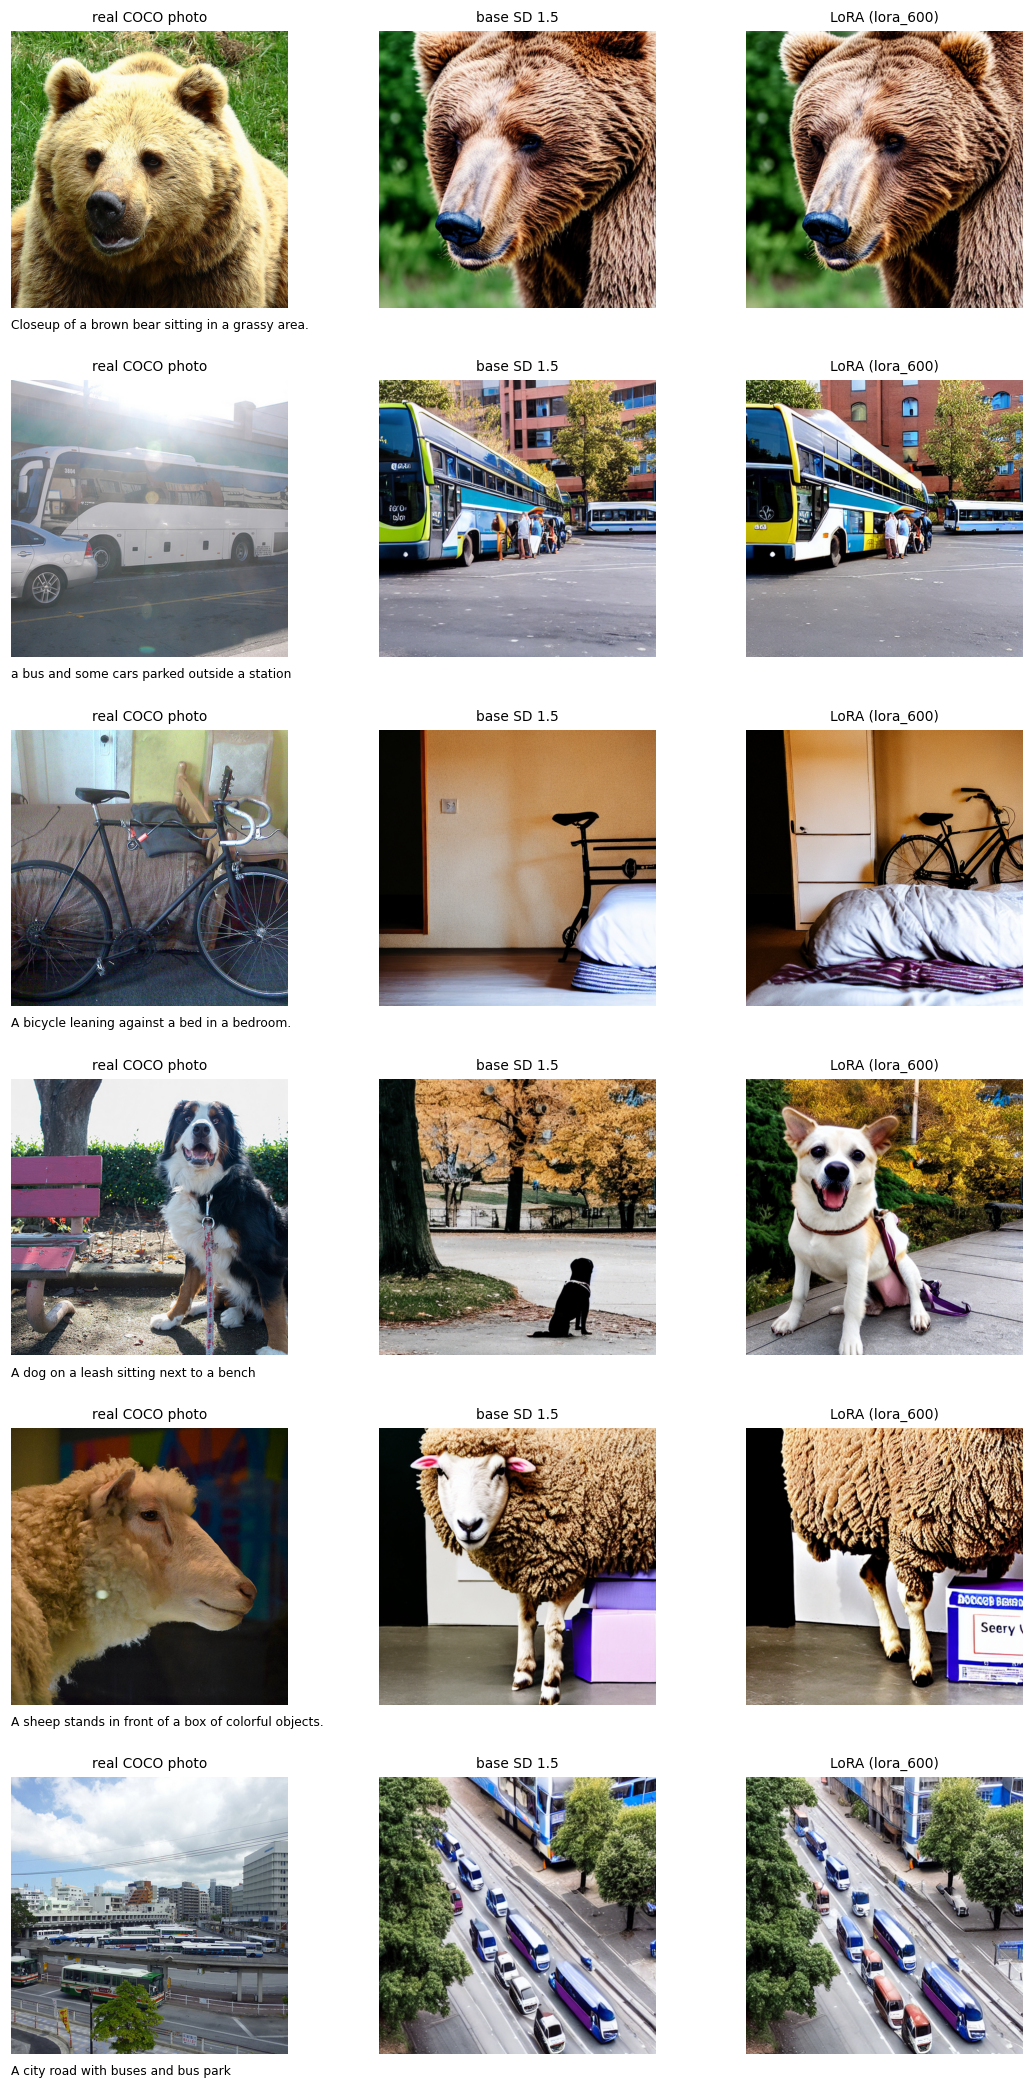

In [17]:
def show_grid(rows, n=6, seed=CFG.main_seed, name="13_real_base_lora"):
    pick = rows.sample(n, random_state=3)
    fig, ax = plt.subplots(n, 3, figsize=(9.5, 3.2 * n))
    for i, r in enumerate(pick.itertuples()):
        panels = [Image.open(png_path(names[r.image_id])),
                  Image.open(GEN / "eval" / "base" / f"{r.caption_idx}_s{seed}.png"),
                  Image.open(GEN / "eval" / BEST / f"{r.caption_idx}_s{seed}.png")]
        for j, (im, t) in enumerate(zip(panels, ["real COCO photo", "base SD 1.5", f"LoRA ({BEST})"])):
            ax[i, j].imshow(im); ax[i, j].axis("off"); ax[i, j].set_title(t, fontsize=9)
        ax[i, 0].text(0, -0.04, textwrap.fill(r.caption, 55), transform=ax[i, 0].transAxes, fontsize=8, va="top")
    plt.tight_layout(); savefig(name); plt.show()


show_grid(EV)

## 10. Scoring
### 10.1 CLIPScore *(Mukul's metric, now on the frozen split)*
The paired bootstrap resamples captions, as in Mukul's report. Pairs where the safety checker blacked out either image are dropped from both sides.

In [18]:
def paired_bootstrap(a, b, n=CFG.n_boot, seed=0):
    d = np.asarray(b) - np.asarray(a)
    rng = np.random.default_rng(seed)
    boots = d[rng.integers(0, len(d), (n, len(d)))].mean(1)
    return float(d.mean()), float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))


ev_txt_f = clip_text_feats(EV.caption.tolist())
FLAGS = {k: load_flags(GEN / "eval" / k) for k in MODELS}


def scores_for(seed, idx):
    keep = [i for i in idx if all(f"{ev_items[i][0]}_s{seed}" not in FLAGS[k] for k in MODELS)]
    out = {}
    for k in MODELS:
        f = clip_image_feats([GEN / "eval" / k / f"{ev_items[i][0]}_s{seed}.png" for i in keep], desc=f"CLIP {k} s{seed}")
        out[k] = clipscore(f, ev_txt_f[keep])
    return keep, out


keep0, CS = scores_for(CFG.main_seed, range(len(EV)))
d, lo, hi = paired_bootstrap(CS["base"], CS[BEST])
clip_main = {"base": float(CS["base"].mean()), BEST: float(CS[BEST].mean()), "delta": d, "ci95": [lo, hi],
             "win_rate": float((CS[BEST] > CS["base"]).mean()), "n_pairs": len(keep0),
             "flagged": {k: len(v) for k, v in FLAGS.items()}}
print(json.dumps(clip_main, indent=2))

seed_rows = []
for s in (CFG.main_seed,) + tuple(CFG.seed_check_seeds):
    k_, cs_ = scores_for(s, range(CFG.seed_check_n))
    dd, l_, h_ = paired_bootstrap(cs_["base"], cs_[BEST])
    seed_rows.append({"seed": s, "base": cs_["base"].mean(), BEST: cs_[BEST].mean(), "delta": dd, "ci_low": l_, "ci_high": h_, "n": len(k_)})
SEED_TABLE = pd.DataFrame(seed_rows)
display(SEED_TABLE.round(3))
print(f"delta across seeds: mean {SEED_TABLE.delta.mean():.3f}, sd {SEED_TABLE.delta.std(ddof=1):.3f}")
record("clipscore", {"eval": clip_main, "seed_check": SEED_TABLE.to_dict("records")})

CLIP base s0:   0%|          | 0/16 [00:00<?, ?it/s]

CLIP lora_600 s0:   0%|          | 0/16 [00:00<?, ?it/s]

{
  "base": 26.176959991455078,
  "lora_600": 26.587797164916992,
  "delta": 0.4108361601829529,
  "ci95": [
    0.23420396447181702,
    0.5812960863113403
  ],
  "win_rate": 0.608433734939759,
  "n_pairs": 498,
  "flagged": {
    "base": 1,
    "lora_600": 4
  }
}


CLIP base s0:   0%|          | 0/4 [00:00<?, ?it/s]

CLIP lora_600 s0:   0%|          | 0/4 [00:00<?, ?it/s]

CLIP base s1:   0%|          | 0/4 [00:00<?, ?it/s]

CLIP lora_600 s1:   0%|          | 0/4 [00:00<?, ?it/s]

CLIP base s2:   0%|          | 0/4 [00:00<?, ?it/s]

CLIP lora_600 s2:   0%|          | 0/4 [00:00<?, ?it/s]

,seed,base,lora_600,delta,ci_low,ci_high,n
0,0,26.353001,26.871,0.518,0.134,0.912,99
1,1,26.820000,27.399,0.579,0.218,0.952,98
2,2,26.860001,26.948,0.089,-0.402,0.582,99


delta across seeds: mean 0.396, sd 0.267


### 10.2 Image quality: FID, KID, Inception Score *(new)*
FID depends heavily on sample size. Santhosh measured that real photos alone score 98 against other real photos at N = 500. So every generated score here sits next to a **real-photo floor**: the `eval_500` real photos scored against the same `real_ref_b_2000` reference. KID is unbiased at small N, so it is the fairer number for comparing base and LoRA. Images blacked out by the safety checker are left out of every set.

In [19]:
FID_DIR = LOCAL / "fid"


def fill_folder(dst, files):
    if dst.exists():
        shutil.rmtree(dst)
    dst.mkdir(parents=True)
    for i, f in enumerate(files):
        shutil.copy(f, dst / f"{i:05d}.png")
    return dst


kept_names = [ev_items[i][0] for i in keep0]
kept_ids = EV.set_index("caption_idx").loc[kept_names, "image_id"].tolist()
folders = {
    "real_ref_b_2000": fill_folder(FID_DIR / "refb", [png_path(names[i]) for i in refb.image_id]),
    "real eval photos (floor)": fill_folder(FID_DIR / "real_eval", [png_path(names[i]) for i in kept_ids]),
    **{k: fill_folder(FID_DIR / k, [GEN / "eval" / k / f"{n}_s{CFG.main_seed}.png" for n in kept_names]) for k in MODELS},
}


def quality_tf(d_gen, d_ref):
    import torch_fidelity
    m = torch_fidelity.calculate_metrics(input1=str(d_gen), input2=str(d_ref), cuda=True, isc=True, fid=True, kid=True,
                                         kid_subset_size=100, verbose=False)
    return {"FID": m["frechet_inception_distance"], "KID_x1000": 1000 * m["kernel_inception_distance_mean"],
            "IS": m["inception_score_mean"], "IS_std": m["inception_score_std"], "backend": "torch-fidelity"}


def quality_cf(d_gen, d_ref):
    from cleanfid import fid
    return {"FID": fid.compute_fid(str(d_gen), str(d_ref)), "KID_x1000": 1000 * fid.compute_kid(str(d_gen), str(d_ref)),
            "IS": None, "IS_std": None, "backend": "clean-fid"}


# one backend for every set, so the rows are comparable
SETS = ["real eval photos (floor)"] + MODELS
try:
    QUALITY = {name: quality_tf(folders[name], folders["real_ref_b_2000"]) for name in SETS}
except Exception as e:
    print("torch-fidelity failed, using clean-fid for every set (no Inception Score):", repr(e)[:200])
    torch.cuda.empty_cache()
    QUALITY = {name: quality_cf(folders[name], folders["real_ref_b_2000"]) for name in SETS}
QUALITY_TABLE = pd.DataFrame(QUALITY).T
QUALITY_TABLE.insert(0, "N", len(kept_names))
display(QUALITY_TABLE.round(3))

# Is the base-vs-LoRA KID difference real? Inception features once, then a PAIRED bootstrap over captions:
# each resample draws the same captions for both models and recomputes KID against the fixed reference set.
from cleanfid import fid as cfid
from cleanfid.features import build_feature_extractor
feat_model = build_feature_extractor("clean", torch.device("cuda"))
FEAT = {name: cfid.get_folder_features(str(folders[name]), model=feat_model, num_workers=0, verbose=False)
        for name in ["real_ref_b_2000"] + MODELS}
del feat_model; torch.cuda.empty_cache()


def poly_k(x, y):
    return (x @ y.T / x.shape[1] + 1) ** 3


Y = FEAT["real_ref_b_2000"].astype(np.float64)
Kyy = poly_k(Y, Y); m_ = len(Y)
kyy_term = (Kyy.sum() - np.trace(Kyy)) / (m_ * (m_ - 1))
KM = {}
for k in MODELS:
    X = FEAT[k].astype(np.float64)
    KM[k] = (poly_k(X, X), poly_k(X, Y))


def kid_idx(k, idx):
    Kxx, Kxy = KM[k]
    sub = Kxx[np.ix_(idx, idx)]
    n_ = len(idx)
    return (sub.sum() - np.trace(sub)) / (n_ * (n_ - 1)) + kyy_term - 2 * Kxy[idx].mean()


rng = np.random.default_rng(0)
n_k = len(kept_names)
full = {k: kid_idx(k, np.arange(n_k)) for k in MODELS}
boots = []
for _ in range(500):
    idx = rng.integers(0, n_k, n_k)
    boots.append(1000 * (kid_idx(BEST, idx) - kid_idx("base", idx)))
kid_delta = [1000 * (full[BEST] - full["base"]), float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))]
print(f"KID x1000, LoRA - base (paired caption bootstrap, clean-fid features): {kid_delta[0]:+.3f} [{kid_delta[1]:+.3f}, {kid_delta[2]:+.3f}]")
record("image_quality", {"reference": "real_ref_b_2000", "n": len(kept_names), "scores": QUALITY,
                         "kid_x1000_lora_minus_base_ci95": kid_delta})

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth


,N,FID,KID_x1000,IS,IS_std,backend
real eval photos (floor),498,77.133447,-0.143588,17.369878,2.093547,torch-fidelity
base,498,91.091746,5.942266,17.055145,1.131879,torch-fidelity
lora_600,498,88.379185,5.968406,17.374003,1.426259,torch-fidelity


KID x1000, LoRA - base (paired caption bootstrap, clean-fid features): -0.032 [-0.888, +0.940]


### 10.3 Missing objects: two calibrated judges *(new)*
Praniti's labels list the target objects each caption names. Two independent detectors then look at each image:
* **Judge A: Faster R-CNN v2** (torchvision, COCO-trained, score ≥ 0.5). This is the exact detector and threshold Santhosh's pilots used, which missed about 1 in 5 real objects.
* **Judge B: OWL-ViT** (open-vocabulary, queried as "a photo of a {object}"). It is a different architecture trained on different data, so its mistakes should not line up with Judge A's.

An object counts as **missing only when both judges miss it**. Both are first run on the **real photos**, where every target is known to be present, so each judge's own miss rate is measured instead of assumed.

In [20]:
import torchvision
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights
from transformers import OwlViTProcessor, OwlViTForObjectDetection

det_w = FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT                 # the same detector as Santhosh's pilots
detector = fasterrcnn_resnet50_fpn_v2(weights=det_w).to(DEVICE).eval()
DET_CATS = det_w.meta["categories"]
det_tf = det_w.transforms()
owl_proc = OwlViTProcessor.from_pretrained(CFG.owl_id)
owl = OwlViTForObjectDetection.from_pretrained(CFG.owl_id).to(DEVICE).eval()
QUERIES = [f"a photo of a {c}" for c in COCO_CLASSES]


@torch.no_grad()
def judge_detector(paths, batch=8):
    # per image: {category: (max score, count of boxes >= threshold)}
    out = []
    for i in tqdm(range(0, len(paths), batch), desc="Faster R-CNN", leave=False):
        ims = [det_tf(Image.open(p).convert("RGB")).to(DEVICE) for p in paths[i:i + batch]]
        for o in detector(ims):
            d = {}
            for lab, sc in zip(o["labels"].tolist(), o["scores"].tolist()):
                c = DET_CATS[lab]
                best, cnt = d.get(c, (0.0, 0))
                d[c] = (max(best, sc), cnt + (sc >= CFG.det_score))
            out.append(d)
    return out


@torch.no_grad()
def judge_owl(paths, batch=8):
    # per image: array of 80 scores, the max over boxes of each query's probability
    out = []
    for i in tqdm(range(0, len(paths), batch), desc="OWL-ViT", leave=False):
        ims = [Image.open(p).convert("RGB") for p in paths[i:i + batch]]
        inp = owl_proc(text=[QUERIES] * len(ims), images=ims, return_tensors="pt").to(DEVICE)
        logits = owl(**inp).logits                       # (batch, boxes, queries)
        out.extend(torch.sigmoid(logits).max(1).values.float().cpu().numpy())
    return out


def judge_targets(paths_by_caption, targets):
    # one row per target: does each judge see it in that caption's image?
    cap_list = list(paths_by_caption)
    paths = [paths_by_caption[c] for c in cap_list]
    A, B = judge_detector(paths), judge_owl(paths)
    pos = {c: i for i, c in enumerate(cap_list)}
    rows = []
    for t in targets.itertuples():
        if t.caption_idx not in pos:
            continue
        i = pos[t.caption_idx]
        a = A[i].get(t.category, (0.0, 0))[0] >= CFG.det_score
        b = B[i][COCO_CLASSES.index(t.category)] >= CFG.owl_threshold
        rows.append({"caption_idx": t.caption_idx, "category": t.category, "words": t.words, "judge_A": a, "judge_B": b,
                     "present": a or b, "missing": not (a or b)})
    return pd.DataFrame(rows)


def fmt3(v):
    return f"{v[0]:+.3f} [{v[1]:+.3f}, {v[2]:+.3f}]"


def cohen_kappa(a, b):
    a, b = np.asarray(a, bool), np.asarray(b, bool)
    po = (a == b).mean(); pe = a.mean() * b.mean() + (1 - a.mean()) * (1 - b.mean())
    return float((po - pe) / (1 - pe)) if pe < 1 else 1.0


T_KEEP = TARGETS[TARGETS.caption_idx.isin(kept_names)]
id_of = dict(zip(EV.caption_idx, EV.image_id))
JUDGED = {"real photos": judge_targets({c: png_path(names[id_of[c]]) for c in kept_names}, T_KEEP)}
for k in MODELS:
    JUDGED[k] = judge_targets({c: GEN / "eval" / k / f"{c}_s{CFG.main_seed}.png" for c in kept_names}, T_KEEP)


def summarise(df):
    np_ = df[df.category != "person"]
    return {"targets": len(df), "judge_A_recall": df.judge_A.mean(), "judge_B_recall": df.judge_B.mean(),
            "recall_either": df.present.mean(), "recall_non_person": np_.present.mean(),
            "missing_rate": df.missing.mean(), "judges_agree": (df.judge_A == df.judge_B).mean(),
            "kappa": cohen_kappa(df.judge_A, df.judge_B)}


RECALL_TABLE = pd.DataFrame({k: summarise(v) for k, v in JUDGED.items()}).T
display(RECALL_TABLE.round(3))

def cluster_paired_bootstrap(df_a, df_b, col, cluster="caption_idx", n=CFG.n_boot, seed=0):
    # paired difference (b - a) in the mean of `col`, resampling whole captions (targets in one image are correlated)
    ga = df_a.groupby(cluster)[col].agg(["sum", "count"]); gb = df_b.groupby(cluster)[col].agg(["sum", "count"]).loc[ga.index]
    sa, ca, sb, cb = (v.values.astype(float) for v in (ga["sum"], ga["count"], gb["sum"], gb["count"]))
    d = sb.sum() / cb.sum() - sa.sum() / ca.sum()
    rng = np.random.default_rng(seed)
    ix = rng.integers(0, len(sa), (n, len(sa)))
    bd = sb[ix].sum(1) / cb[ix].sum(1) - sa[ix].sum(1) / ca[ix].sum(1)
    return float(d), float(np.percentile(bd, 2.5)), float(np.percentile(bd, 97.5))


recall_deltas = {}
for col in ("present", "judge_A", "judge_B"):                # combined verdict and each judge on its own
    recall_deltas[col] = cluster_paired_bootstrap(JUDGED["base"], JUDGED[BEST], col)
    print(f"object recall ({col}), LoRA - base: {fmt3(recall_deltas[col])}")
rd, rlo, rhi = recall_deltas["present"]

per_cat = pd.DataFrame({k: v[v.category != "person"].groupby("category").present.mean() for k, v in JUDGED.items()})
per_cat["n"] = JUDGED["base"][JUDGED["base"].category != "person"].groupby("category").size()
display(per_cat[per_cat.n >= 5].sort_values("base").round(2).head(15))
for k, v in JUDGED.items():
    v.to_csv(RES_DIR / f"object_recall_{k.replace(' ', '_')}.csv", index=False)
record("object_recall", {"table": RECALL_TABLE.to_dict("index"), "lora_minus_base": recall_deltas,
                         "note": "CIs resample captions; OWL-ViT false positives are not measured, so judge_A alone is the conservative view"})

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100%|██████████| 167M/167M [00:01<00:00, 171MB/s]


preprocessor_config.json:   0%|          | 0.00/392 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.42k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/775 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.06M [00:00<?, ?B/s]

... (10 outputs left out)

OWL-ViT:   0%|          | 0/63 [00:00<?, ?it/s]

,targets,judge_A_recall,judge_B_recall,recall_either,recall_non_person,missing_rate,judges_agree,kappa
real photos,566.0,0.965,0.935,0.984,0.978,0.016,0.931,0.283
base,566.0,0.898,0.848,0.938,0.923,0.062,0.869,0.414
lora_600,566.0,0.922,0.873,0.942,0.921,0.058,0.912,0.523


object recall (present), LoRA - base: +0.004 [-0.016, +0.023]
object recall (judge_A), LoRA - base: +0.025 [+0.004, +0.047]
object recall (judge_B), LoRA - base: +0.025 [-0.002, +0.052]


,real photos,base,lora_600,n
category,,,,
suitcase,1.00,0.33,0.50,6
airplane,1.00,0.73,0.91,11
toilet,0.89,0.78,0.67,9
couch,1.00,0.80,1.00,5
bench,1.00,0.83,0.75,12
sheep,1.00,0.86,0.86,7
bear,1.00,0.86,1.00,7
car,1.00,0.87,1.00,15
bicycle,1.00,0.89,1.00,9


### 10.4 Stress prompts *(Praniti's prompts, scored for the first time)*
* **Multi-object:** does the image contain all three named objects (either judge)?
* **Counting:** does the detector count exactly the requested number? Instances need a score ≥ 0.5, and only Judge A is used, because OWL-ViT doesn't count reliably.

In [21]:
st_items = [(r.prompt_id, STATES_STRESS[ROW_STRESS[r.prompt_id]]) for r in STRESS_USED.itertuples()]
stress_rows = []
for k in MODELS:
    out = gen_images("stress", k, st_items, [CFG.main_seed])
    flagged = load_flags(out)
    paths = [out / f"{pid}_s{CFG.main_seed}.png" for pid, _ in st_items]
    A, B = judge_detector(paths), judge_owl(paths)
    for (pid, _), r, a_, b_ in zip(st_items, STRESS_USED.itertuples(), A, B):
        if f"{pid}_s{CFG.main_seed}" in flagged:
            continue
        objs = json.loads(r.objects)
        seen = [(a_.get(o, (0, 0))[0] >= CFG.det_score) or (b_[COCO_CLASSES.index(o)] >= CFG.owl_threshold) for o in objs]
        row = {"model": k, "prompt_id": pid, "family": r.family, "prompt": r.prompt, "all_present": all(seen),
               "share_present": float(np.mean(seen))}
        if r.family == "counting":
            want = list(json.loads(r.expected)["count"].values())[0]
            got = a_.get(objs[0], (0, 0))[1]
            row.update({"count_wanted": want, "count_detected": got, "count_correct": got == want})
        stress_rows.append(row)
STRESS_RES = pd.DataFrame(stress_rows)
if "count_correct" not in STRESS_RES:
    STRESS_RES["count_correct"] = np.nan
STRESS_RES.to_csv(RES_DIR / "stress_results.csv", index=False)
summary = STRESS_RES.groupby(["family", "model"]).agg(all_present=("all_present", "mean"), share_present=("share_present", "mean"),
                                                     count_correct=("count_correct", "mean"), n=("prompt_id", "size"))
display(summary.round(3))
record("stress", summary.reset_index().to_dict("records"))

stress/base:   0%|          | 0/80 [00:00<?, ?it/s]

Faster R-CNN:   0%|          | 0/10 [00:00<?, ?it/s]

OWL-ViT:   0%|          | 0/10 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


stress/lora_600:   0%|          | 0/80 [00:00<?, ?it/s]

Faster R-CNN:   0%|          | 0/10 [00:00<?, ?it/s]

OWL-ViT:   0%|          | 0/10 [00:00<?, ?it/s]

all_present  share_present count_correct   n
family       model                                                 
counting     base            1.000          1.000         0.275  40
             lora_600        1.000          1.000         0.325  40
multi_object base            0.150          0.633           NaN  40
             lora_600        0.175          0.658           NaN  40

## 11. Headline experiment: does fine-tuning change *when* the model commits to each word?
Santhosh's **commit step** is the first denoising step after which a word's attention map stays correlated (r ≥ 0.8) with its final layout. In his examples a late commit went with a missing object (the cat committed at step 14 of 20 and never appeared), but he hadn't tested that at scale or on a fine-tuned model.

For the first `n_timing` test captions with a non-person target, I record cross-attention with his recorder for both models, using the same seed. For each target word I measure:
* its **commit step** at thresholds 0.7, 0.8 and 0.9, with word pieces joined (Praniti's split-word rule);
* its **average share** of word-directed attention.

Then I ask two questions:
1. Does LoRA shift commit steps for the same word in the same caption?
2. Does a late commit predict that the object is missing, using the two-judge verdict from §10.3?

The recorder copies the attention on the side and leaves the image unchanged. As a check, each recorded image is compared with the image already saved in §9.

In [22]:
GRID = 64


class AttentionStore:
    # Santhosh: per-step token maps, head-averaged, upsampled to 64x64, averaged over the 16 cross-attention layers
    def __init__(self):
        self.reset()

    def reset(self):
        self.maps, self.step, self._acc, self._layers = {}, 0, None, 0

    def add(self, probs_cond):
        heads, n, t = probs_cond.shape
        res = int(round(n ** 0.5))
        m = probs_cond.mean(0).float().T.reshape(t, res, res)
        if res != GRID:
            m = F.interpolate(m[None], size=(GRID, GRID), mode="bilinear", align_corners=False)[0]
        self._acc = m if self._acc is None else self._acc + m
        self._layers += 1

    def end_step(self):
        if self._acc is not None:
            self.maps[self.step] = (self._acc / self._layers).half().cpu()
        self._acc, self._layers = None, 0
        self.step += 1

    def stacked(self):
        return np.stack([self.maps[s].numpy() for s in sorted(self.maps)])


class RecordingCrossAttnProcessor:
    # Santhosh: the image comes from the stock processor; probabilities are recomputed on the side for recording only
    def __init__(self, store, inner):
        self.store, self.inner = store, inner

    @torch.no_grad()
    def _record(self, attn, hidden_states, encoder_hidden_states, attention_mask, temb):
        if getattr(attn, "spatial_norm", None) is not None:
            hidden_states = attn.spatial_norm(hidden_states, temb)
        if hidden_states.ndim == 4:
            b, c, h, w = hidden_states.shape
            hidden_states = hidden_states.view(b, c, h * w).transpose(1, 2)
        batch, n, _ = hidden_states.shape
        assert batch in (1, 2), f"record one prompt at a time (got batch {batch})"
        if getattr(attn, "group_norm", None) is not None:
            hidden_states = attn.group_norm(hidden_states.transpose(1, 2)).transpose(1, 2)
        if getattr(attn, "norm_cross", None):
            encoder_hidden_states = attn.norm_encoder_hidden_states(encoder_hidden_states)
        sl = slice(batch // 2, batch) if batch == 2 else slice(0, batch)         # conditional branch only
        hs, enc = hidden_states[sl], encoder_hidden_states[sl]
        heads = attn.heads
        q, k = attn.to_q(hs), attn.to_k(enc)                                     # includes the LoRA update when loaded
        d = q.shape[-1] // heads
        q = q.view(q.shape[0], n, heads, d).transpose(1, 2).float()
        k = k.view(k.shape[0], -1, heads, d).transpose(1, 2).float()
        for p in (torch.matmul(q, k.transpose(-1, -2)) * attn.scale).softmax(dim=-1):
            self.store.add(p)

    def __call__(self, attn, hidden_states, encoder_hidden_states=None, attention_mask=None, temb=None, *args, **kwargs):
        if encoder_hidden_states is not None:
            self._record(attn, hidden_states, encoder_hidden_states, attention_mask, temb)
        return self.inner(attn, hidden_states, encoder_hidden_states, attention_mask, temb, *args, **kwargs)


def install_recorder(unet, store):
    original = dict(unet.attn_processors)
    unet.set_attn_processor({n: (RecordingCrossAttnProcessor(store, p) if "attn2" in n else p) for n, p in original.items()})
    return original


def correlation_curve(seq, ref_steps=5, ignore_last=1):
    # Santhosh: Pearson r of each step's map with the mean map of the 5 evaluations before the last one
    seq = seq.astype(np.float32).reshape(seq.shape[0], -1)
    end = len(seq) - ignore_last
    ref = seq[end - ref_steps:end].mean(0)
    ref = (ref - ref.mean()) / (ref.std() + 1e-8)
    z = (seq - seq.mean(1, keepdims=True)) / (seq.std(1, keepdims=True) + 1e-8)
    return (z * ref).mean(1)


def commit_from_curve(corr, threshold, ignore_last=1):
    ok = corr[: len(corr) - ignore_last] >= threshold
    for t in range(len(ok)):
        if ok[t:].all():
            return t
    return None


def target_slots(prompt, phrase):
    # token slots of a target phrase (e.g. "bikes", "teddy bear"), joining CLIP word pieces
    ws = sentence_words(prompt)
    texts = [re.sub(r"[^a-z]", "", w["text"].lower()) for w in ws]
    want = [re.sub(r"[^a-z]", "", p) for p in phrase.lower().split()]
    for i in range(len(texts) - len(want) + 1):
        if texts[i:i + len(want)] == want:
            return [s for w in ws[i:i + len(want)] for s in w["slots"]], [s for w in ws for s in w["slots"]]
    return None, [s for w in ws for s in w["slots"]]


TIMING_CAPS = [c for c in EV.caption_idx if c in set(T_KEEP[T_KEEP.category != "person"].caption_idx)][:CFG.n_timing]
missing_lookup = {(k, r.caption_idx, r.category): r.missing for k, v in JUDGED.items() for r in v.itertuples()}
cap_text = dict(zip(EV.caption_idx, EV.caption))
store = AttentionStore()
timing_rows, recorder_diffs = [], []
for k in MODELS:
    set_model(k)
    original = install_recorder(pipe.unet, store)

    def _cb(p, i, t, kw):
        store.end_step(); return kw

    try:
        for c in tqdm(TIMING_CAPS, desc=f"word timing {k}"):
            store.reset()
            img, _ = paint_embeds(STATES_EV[ROW_EV[c]], CFG.main_seed, callback=_cb)
            recorder_diffs.append(pixel_diff(img, Image.open(GEN / "eval" / k / f"{c}_s{CFG.main_seed}.png")))
            maps = store.stacked()                                               # (steps, 77, 64, 64)
            for t in T_KEEP[(T_KEEP.caption_idx == c) & (T_KEEP.category != "person")].itertuples():
                slots, all_slots = target_slots(cap_text[c], t.words)
                if not slots:
                    continue
                seq = maps[:, slots].astype(np.float32).mean(1)
                corr = correlation_curve(seq)
                mass = maps[:, all_slots].astype(np.float32).mean(axis=(2, 3))
                share = maps[:, slots].astype(np.float32).mean(axis=(2, 3)).sum(1) / mass.sum(1)
                row = {"model": k, "caption_idx": c, "category": t.category, "word": t.words, "n_steps": len(maps),
                       "share_mean": float(share.mean()), "final_step_drop": float(corr[-2] - corr[-1]),
                       "missing": missing_lookup.get((k, c, t.category))}
                for th in CFG.commit_thresholds_sweep:
                    row[f"commit_{th}"] = commit_from_curve(corr, th)
                timing_rows.append(row)
    finally:
        pipe.unet.set_attn_processor(original)

TIMING = pd.DataFrame(timing_rows)
TIMING.to_csv(RES_DIR / "word_timing.csv", index=False)
print(f"{len(TIMING)} target words timed; recorder vs saved images: max mean pixel difference {max(recorder_diffs):.3f}")

word timing base:   0%|          | 0/60 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


word timing lora_600:   0%|          | 0/60 [00:00<?, ?it/s]

128 target words timed; recorder vs saved images: max mean pixel difference 0.000


share of target words that never settle: {'base': '0.0%', 'lora_600': '0.0%'}
{
  "words_paired": 64,
  "commit_shift_lora_minus_base": [
    -0.140625,
    -1.0625248015873017,
    0.8000819672131136
  ],
  "both_never_settle": 0,
  "never_settle_share": {
    "base": 0.0,
    "lora_600": 0.0
  },
  "wilcoxon_p": 0.9500889729198767,
  "share_shift_lora_minus_base": [
    -0.0032791923731565475,
    -0.005962144911728813,
    -0.0007429329456672808
  ],
  "prediction_per_model": {
    "base": {
      "n_words": 64,
      "n_missing": 6,
      "AUC commit@0.7": [
        0.8347701149425288,
        0.629833156779661,
        0.965532883759733
      ],
      "AUC commit@0.8": [
        0.8577586206896551,
        0.7627118644067797,
        0.9446967213114754
      ],
      "AUC commit@0.9": [
        0.7988505747126436,
        0.6589931073025335,
        0.9128931873211533
      ],
      "AUC low attention share": [
        0.8074712643678161,
        0.5666666666666667,
        0.9766

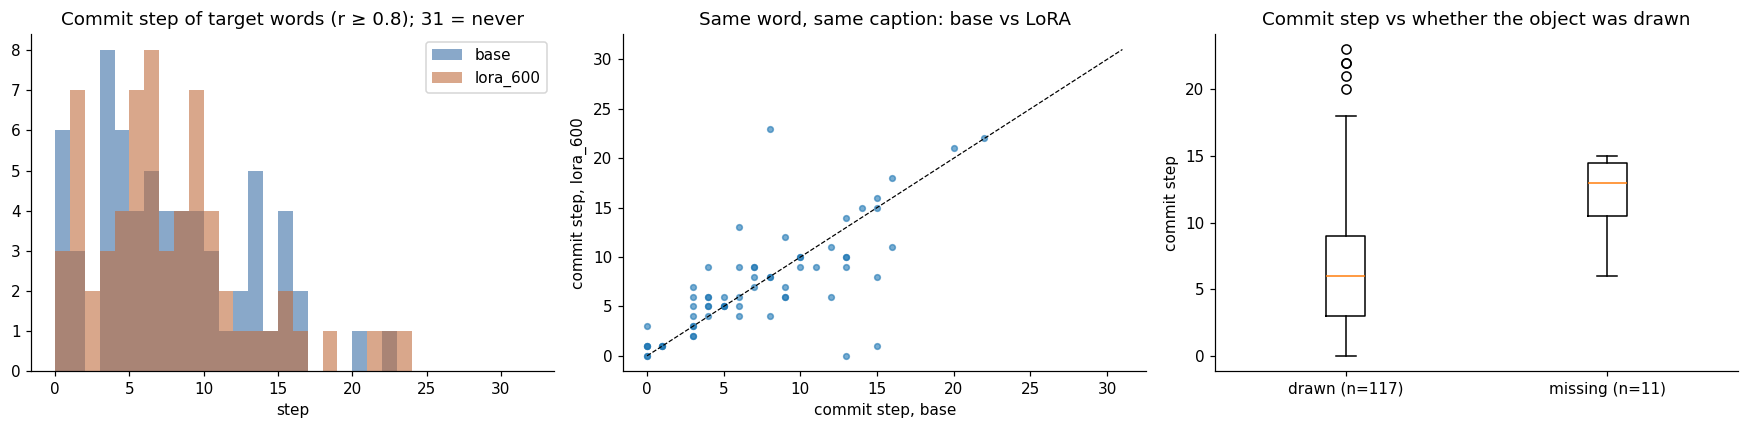

In [23]:
from scipy.stats import wilcoxon, spearmanr
from sklearn.metrics import roc_auc_score

CC = f"commit_{CFG.commit_threshold}"
nsteps = int(TIMING.n_steps.max())      # PNDM: 31 UNet evaluations for 30 steps (the extra one is at the start)
never = {k: float(TIMING[TIMING.model == k][CC].isna().mean()) for k in MODELS}
print("share of target words that never settle:", {k: f"{v:.1%}" for k, v in never.items()})
T2 = TIMING.copy()
for th in CFG.commit_thresholds_sweep:
    T2[f"commit_{th}"] = T2[f"commit_{th}"].fillna(nsteps)          # "never settles" = after the last evaluation


def paired_wide(col):
    return T2.pivot_table(index=["caption_idx", "category"], columns="model", values=col).dropna().reset_index()


def caption_boot_shift(wide, n=CFG.n_boot, seed=0):
    # mean (LoRA - base) over words, resampling whole captions
    d = (wide[BEST] - wide["base"]).values
    groups = wide.caption_idx.values
    caps_u = np.unique(groups); by = [d[groups == c] for c in caps_u]
    rng = np.random.default_rng(seed)
    bs = []
    for _ in range(n):
        pick = rng.integers(0, len(caps_u), len(caps_u))
        bs.append(np.concatenate([by[i] for i in pick]).mean())
    return float(d.mean()), float(np.percentile(bs, 2.5)), float(np.percentile(bs, 97.5))


wide = paired_wide(CC)
shift_ci = caption_boot_shift(wide)
both_never = int(((wide["base"] == nsteps) & (wide[BEST] == nsteps)).sum())
try:
    p_w = float(wilcoxon(wide["base"], wide[BEST]).pvalue) if (wide[BEST] != wide["base"]).any() else 1.0
except ValueError:
    p_w = float("nan")
share_ci = caption_boot_shift(paired_wide("share_mean"))


def auc_ci(df, score, n=1000, seed=0):
    # AUC of `score` for predicting a missing object, with a caption-level bootstrap interval
    y = df.missing.astype(int).values
    if not 0 < y.sum() < len(y):
        return None
    a = float(roc_auc_score(y, score(df)))
    caps_u = df.caption_idx.unique(); rng = np.random.default_rng(seed); bs = []
    idx_by = {c: np.where(df.caption_idx.values == c)[0] for c in caps_u}
    for _ in range(n):
        ix = np.concatenate([idx_by[c] for c in rng.choice(caps_u, len(caps_u))])
        yb = y[ix]
        if 0 < yb.sum() < len(yb):
            bs.append(roc_auc_score(yb, score(df.iloc[ix])))
    return [a, float(np.percentile(bs, 2.5)), float(np.percentile(bs, 97.5))]


pred = {}
for k in MODELS:                                                    # per model: no caption is counted twice
    lab = T2[(T2.model == k)].dropna(subset=["missing"]).reset_index(drop=True)
    lab["missing"] = lab.missing.astype(bool)
    pred[k] = {"n_words": int(len(lab)), "n_missing": int(lab.missing.sum())}
    for th in CFG.commit_thresholds_sweep:
        pred[k][f"AUC commit@{th}"] = auc_ci(lab, lambda d, th=th: d[f"commit_{th}"].values)
    pred[k]["AUC low attention share"] = auc_ci(lab, lambda d: -d.share_mean.values)
    pred[k]["AUC final-step drop"] = auc_ci(lab, lambda d: d.final_step_drop.values)

timing_res = {"words_paired": int(len(wide)), "commit_shift_lora_minus_base": list(shift_ci), "both_never_settle": both_never,
              "never_settle_share": never, "wilcoxon_p": p_w, "share_shift_lora_minus_base": list(share_ci),
              "prediction_per_model": pred, "median_commit": T2.groupby("model")[CC].median().to_dict(),
              "step_note": "PNDM records 31 evaluations for 30 steps; evaluation k >= 2 is scheduler step k-1"}
print(json.dumps(timing_res, indent=2, default=to_py))
record("word_timing", timing_res)
lab = T2.dropna(subset=["missing"]).copy(); lab["missing"] = lab.missing.astype(bool)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
bins = np.arange(0, nsteps + 2)
for k, c in zip(MODELS, ["#3b6ea5", "#c06c3e"]):
    ax[0].hist(T2[T2.model == k][CC], bins=bins, alpha=0.6, label=k, color=c)
ax[0].set(title=f"Commit step of target words (r ≥ {CFG.commit_threshold}); {nsteps} = never", xlabel="step"); ax[0].legend()
ax[1].scatter(wide["base"], wide[BEST], s=14, alpha=0.6)
ax[1].plot([0, nsteps], [0, nsteps], "k--", lw=0.8)
ax[1].set(title="Same word, same caption: base vs LoRA", xlabel="commit step, base", ylabel=f"commit step, {BEST}")
groups = [lab[~lab.missing][CC], lab[lab.missing][CC]]
ax[2].boxplot(groups)
ax[2].set_xticks([1, 2]); ax[2].set_xticklabels([f"drawn (n={len(groups[0])})", f"missing (n={len(groups[1])})"])
ax[2].set(title="Commit step vs whether the object was drawn", ylabel="commit step")
plt.tight_layout(); savefig("14_word_timing"); plt.show()

## 12. Text encoders compared without training *(Praniti, with my additions)*
This is Praniti's comparison of CLIP, BERT, T5, GPT-2 and a TF-IDF word-count baseline on the 2,000 test captions. I add two things:
* **Bootstrap 95% intervals** on paraphrase retrieval, scene clustering and CKA, which Santhosh asked for, so the rankings can be checked for overlap.
* **A corrected word-order and colour test.** In the original, the "same meaning" sentence moved a whole phrase while the "changed meaning" sentence swapped only two words, so the test measured sentence structure instead of meaning (Praniti noted this herself). Here the same-meaning version changes **one word for a synonym** and keeps the structure, so only the meaning differs between the two sides.

In [24]:
if CFG.run_encoder_comparison:
    from transformers import AutoModel, AutoTokenizer, T5EncoderModel
    from sklearn.feature_extraction.text import TfidfVectorizer
    ENCODERS = {"CLIP ViT-L/14": "sd_text_encoder", "BERT-base": "google-bert/bert-base-uncased",
                "T5-base": "google-t5/t5-base", "GPT-2": "openai-community/gpt2"}

    other = caps[caps.image_id.isin(ev2000.image_id) & ~caps.caption_idx.isin(ev2000.caption_idx)]
    para = other.groupby("image_id").first().reindex(ev2000.image_id).caption.tolist()
    cat_super = {c["id"]: c["supercategory"] for c in inst_json["categories"]}
    largest = {}
    for a_ in inst_json["annotations"]:
        if a_["image_id"] not in largest or a_["area"] > largest[a_["image_id"]][0]:
            largest[a_["image_id"]] = (a_["area"], cat_super[a_["category_id"]])
    scene = np.array([largest.get(i, (0, "none"))[1] for i in ev2000.image_id])

    def stress_triplets(seed):
        # Praniti: replays the stress-prompt draws -> (original, same meaning [moved phrase], changed meaning)
        rng = random.Random(seed)
        pairs = set()
        while len(pairs) < 20:
            a, b = rng.sample(ANIMALS, 2); pairs.add((a, b, rng.choice(VERBS), rng.choice(SCENES)))
        order = [(a, b, v, s) for a, b, v, s in sorted(pairs)]
        seen = set()
        while len(seen) < 40:
            seen.add((rng.choice(ANIMALS + THINGS), rng.choice(list(NUMBERS))))
        colour, seen = [], set()
        while len(colour) < 40:
            a, b = rng.sample(THINGS, 2); ca, cb = rng.sample(COLOURS, 2)
            if (a, b, ca, cb) not in seen:
                seen.add((a, b, ca, cb)); colour.append((a, b, ca, cb))
        return order, colour

    VERB_SYN = {"chasing": "pursuing", "looking at": "watching", "standing next to": "standing beside",
                "following": "trailing", "sitting behind": "sitting in back of"}
    ORDER, COLOUR = stress_triplets(CFG.seed_stress)
    TRIPLETS = {
        "word order (original test)": [(f"{article(a)} {a} {v} {article(b)} {b} {s}", f"{s} {article(a)} {a} {v} {article(b)} {b}",
                                        f"{article(b)} {b} {v} {article(a)} {a} {s}") for a, b, v, s in ORDER],
        "word order (fixed: verb synonym)": [(f"{article(a)} {a} {v} {article(b)} {b} {s}", f"{article(a)} {a} {VERB_SYN[v]} {article(b)} {b} {s}",
                                              f"{article(b)} {b} {v} {article(a)} {a} {s}") for a, b, v, s in ORDER],
        "colour (original test)": [(f"{article(ca)} {ca} {a} and {article(cb)} {cb} {b}", f"{article(cb)} {cb} {b} and {article(ca)} {ca} {a}",
                                    f"{article(cb)} {cb} {a} and {article(ca)} {ca} {b}") for a, b, ca, cb in COLOUR],
        "colour (fixed: 'and' -> 'along with')": [(f"{article(ca)} {ca} {a} and {article(cb)} {cb} {b}",
                                                   f"{article(ca)} {ca} {a} along with {article(cb)} {cb} {b}",
                                                   f"{article(cb)} {cb} {a} and {article(ca)} {ca} {b}") for a, b, ca, cb in COLOUR],
    }
    assert TRIPLETS["word order (original test)"][0][0] == STRESS[STRESS.family == "word_order"].prompt.iloc[0]

    texts = {"captions": ev2000.caption.tolist(), "paraphrases": para}
    for tname, trip in TRIPLETS.items():
        for j, part in enumerate(("orig", "same", "changed")):
            texts[f"{tname}|{part}"] = [t[j] for t in trip]

    def load_encoder(ref):
        if ref == "sd_text_encoder":
            return sd_tokenizer, text_encoder
        tok = AutoTokenizer.from_pretrained(ref)
        model = T5EncoderModel.from_pretrained(ref) if "t5" in ref else AutoModel.from_pretrained(ref)
        if tok.pad_token is None:
            tok.pad_token = tok.eos_token
        return tok, model.to(DEVICE).eval()

    @torch.no_grad()
    def embed(tok, model, ref, tx, batch=64):
        sent, eos = [], []
        for i in range(0, len(tx), batch):
            enc = tok(list(tx[i:i + batch]), padding=True, truncation=True, max_length=77, return_tensors="pt", return_special_tokens_mask=True)
            special = enc.pop("special_tokens_mask")
            enc = {k_: v_.to(DEVICE) for k_, v_ in enc.items()}
            out = model(**enc)
            h = out.last_hidden_state.float()
            keep = (enc["attention_mask"].bool() & ~special.to(DEVICE).bool()).float().unsqueeze(-1)
            sent.append((h * keep).sum(1) / keep.sum(1).clamp(min=1))
            if ref == "sd_text_encoder":
                eos.append(out.pooler_output.float())
        r = {"sent": torch.cat(sent).cpu().numpy()}
        if eos:
            r["eos"] = torch.cat(eos).cpu().numpy()
        return r

    EMB = defaultdict(dict)
    for name, ref in ENCODERS.items():
        tok, model = load_encoder(ref)
        for key, tx in texts.items():
            r = embed(tok, model, ref, tx)
            EMB[name][key] = r["sent"]
            if "eos" in r:
                EMB["CLIP (EOS)"][key] = r["eos"]
        if ref != "sd_text_encoder":
            del model; torch.cuda.empty_cache()
    tfidf = TfidfVectorizer(lowercase=True, token_pattern=r"[a-zA-Z]+").fit(caps.caption)
    for key, tx in texts.items():
        EMB["TF-IDF words"][key] = tfidf.transform(tx).toarray().astype(np.float32)
    REPS = ["CLIP ViT-L/14", "CLIP (EOS)", "BERT-base", "T5-base", "GPT-2", "TF-IDF words"]
    print("embedded", len(texts), "text sets with", len(REPS), "representations")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

... (13 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

embedded 14 text sets with 6 representations


,paraphrase R@1,R@1 low,R@1 high,10-NN scene,scene low,scene high,CKA vs CLIP,CKA low,CKA high
representation,,,,,,,,,
CLIP ViT-L/14,0.214,0.196,0.233,0.700,0.679,0.720,1.000,1.000,1.000
CLIP (EOS),0.340,0.318,0.360,0.745,0.726,0.764,0.791,0.792,0.806
BERT-base,0.130,0.116,0.146,0.658,0.636,0.678,0.528,0.530,0.551
T5-base,0.154,0.139,0.170,0.684,0.664,0.704,0.600,0.605,0.622
GPT-2,0.034,0.026,0.042,0.560,0.538,0.582,0.132,0.124,0.147
TF-IDF words,0.200,0.182,0.217,0.644,0.623,0.665,0.511,0.531,0.545


Pass rate: is the same-meaning sentence closer than the meaning-changed one? (0.5 = chance)


,word order (original test),word order (fixed: verb synonym),colour (original test),colour (fixed: 'and' -> 'along with')
representation,,,,
CLIP ViT-L/14,0.0,1.00,0.000,1.000
CLIP (EOS),0.0,0.45,0.425,0.725
BERT-base,0.0,0.00,0.000,0.000
T5-base,0.0,0.15,0.000,0.025
GPT-2,0.0,0.35,0.038,0.250
TF-IDF words,0.5,0.00,0.500,0.000


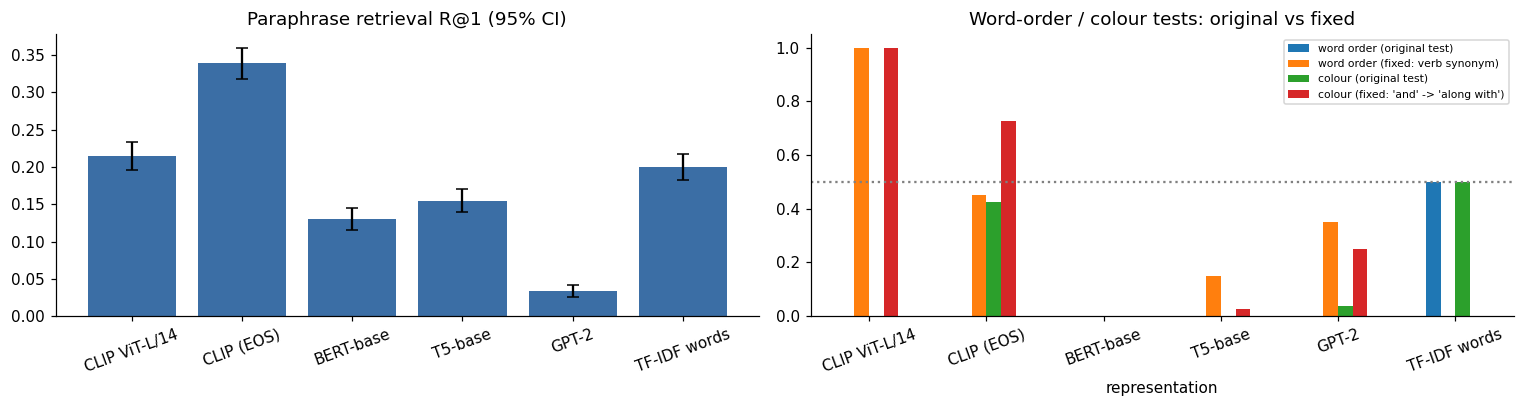

In [25]:
if CFG.run_encoder_comparison:
    def l2n(x):
        return x / np.clip(np.linalg.norm(x, axis=1, keepdims=True), 1e-8, None)

    def centred_gram(x):
        k = (x.astype(np.float64)) @ (x.astype(np.float64)).T
        return k - k.mean(0, keepdims=True) - k.mean(1, keepdims=True) + k.mean()

    def cka_from_grams(kx, ky):
        return float((kx * ky).sum() / (np.linalg.norm(kx) * np.linalg.norm(ky)))

    def linear_cka(x, y):
        # same value as Praniti's feature-space formula, computed on 2,000 x 2,000 Gram matrices (fast for TF-IDF)
        return cka_from_grams(centred_gram(x), centred_gram(y))

    def gram_sub(k, ix):
        s_ = k[np.ix_(ix, ix)]
        return s_ - s_.mean(0, keepdims=True) - s_.mean(1, keepdims=True) + s_.mean()

    RAW_GRAM = {r: (lambda x: x.astype(np.float64) @ x.astype(np.float64).T)(EMB[r]["captions"]) for r in REPS}

    def boot_ci(values, n=2000, seed=0):
        v = np.asarray(values, float); rng = np.random.default_rng(seed)
        b = v[rng.integers(0, len(v), (n, len(v)))].mean(1)
        return float(v.mean()), float(np.percentile(b, 2.5)), float(np.percentile(b, 97.5))

    rng = np.random.default_rng(0)
    boot_idx = [rng.integers(0, len(ev2000), len(ev2000)) for _ in range(200)]
    rows = []
    for r in REPS:
        q, g = l2n(EMB[r]["captions"]), l2n(EMB[r]["paraphrases"])
        sims_ = q @ g.T
        ranks_ = (sims_ > np.diag(sims_)[:, None]).sum(1)
        r1 = boot_ci(ranks_ < 1)
        s = q @ q.T; np.fill_diagonal(s, -np.inf)
        nn = np.argsort(-s, axis=1)[:, :10]
        knn_hit = np.array([Counter(scene[row]).most_common(1)[0][0] for row in nn]) == scene
        kn = boot_ci(knn_hit)
        ck = linear_cka(EMB[r]["captions"], EMB["CLIP ViT-L/14"]["captions"])
        ck_b = [cka_from_grams(gram_sub(RAW_GRAM[r], ix), gram_sub(RAW_GRAM["CLIP ViT-L/14"], ix)) for ix in boot_idx]
        rows.append({"representation": r, "paraphrase R@1": r1[0], "R@1 low": r1[1], "R@1 high": r1[2],
                     "10-NN scene": kn[0], "scene low": kn[1], "scene high": kn[2],
                     "CKA vs CLIP": ck, "CKA low": float(np.percentile(ck_b, 2.5)), "CKA high": float(np.percentile(ck_b, 97.5))})
    ENC_TABLE = pd.DataFrame(rows).set_index("representation")
    display(ENC_TABLE.round(3))

    trip_rows = []
    for r in REPS:
        row = {"representation": r}
        for tname in TRIPLETS:
            o, sm, ch = (l2n(EMB[r][f"{tname}|{p}"]) for p in ("orig", "same", "changed"))
            s_same, s_ch = (o * sm).sum(1), (o * ch).sum(1)
            passed = np.where(np.isclose(s_same, s_ch, atol=1e-6), 0.5, (s_same > s_ch).astype(float))
            row[tname] = float(passed.mean())
        trip_rows.append(row)
    TRIP_TABLE = pd.DataFrame(trip_rows).set_index("representation")
    print("Pass rate: is the same-meaning sentence closer than the meaning-changed one? (0.5 = chance)")
    display(TRIP_TABLE.round(3))

    fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
    xs = np.arange(len(REPS))
    ax[0].bar(xs, ENC_TABLE["paraphrase R@1"], yerr=[ENC_TABLE["paraphrase R@1"] - ENC_TABLE["R@1 low"], ENC_TABLE["R@1 high"] - ENC_TABLE["paraphrase R@1"]],
              color="#3b6ea5", capsize=4)
    ax[0].set_xticks(xs); ax[0].set_xticklabels(REPS, rotation=20); ax[0].set(title="Paraphrase retrieval R@1 (95% CI)")
    TRIP_TABLE.plot.bar(ax=ax[1], rot=20); ax[1].axhline(0.5, color="gray", ls=":")
    ax[1].set(title="Word-order / colour tests: original vs fixed", ylim=(0, 1.05)); ax[1].legend(fontsize=7)
    plt.tight_layout(); savefig("15_encoders"); plt.show()
    record("encoders", {"table": ENC_TABLE.round(4).to_dict("index"), "triplets": TRIP_TABLE.round(4).to_dict("index")})

## 13. Results carried over from teammates *(reported, not rerun here)*
These need more GPU time than a free T4 session allows, or depend on tools that run locally on Santhosh's laptop. The numbers are copied from their reports, with the source named.

| Experiment | Source | Result as reported |
|---|---|---|
| Steering: bias one word's attention inside a box | Santhosh | No strength moved ≥ 4 of 6 objects → pre-registered `NO_STEER` |
| Editing: swap a word from step k | Santhosh | New object appears in all cases at k = 0, falling to 7% at k = 27; a word's own commit step predicts the cut-off no better than one fixed step (ρ = 0.03) |
| Editing: add a detail from step k | Santhosh | Mostly takes only when started by step 3–6; gone by step 18 |
| Moment of loss: when is a missing object lost? | Santhosh | Lost at its own step, median ≈ step 15 of 30 (≈ 12 after removing 6 detector misses); rewinding to the start rescues it about half the time |
| Masked editing | Santhosh | Keeps the scene (0% → 45% kept at step 0) but buys no extra time (median gain 0 steps) |
| Rewind live tool | Santhosh | Exact rewind and branching; a live edit takes 7–9 s on an RTX 5070 laptop |
| CLIP vs BERT through the same trained connector (600 steps) | Mukul | BERT − CLIP = −1.95 CLIPScore [−3.47, −0.50]; with LoRA −2.16 [−3.96, −0.41]; every connector run 11–14 points below base, so the connector is undertrained |

The Faster R-CNN miss rate measured on real photos in §10.3 is a direct check on Santhosh's estimate that his detector "missed about 1 in 5 objects".

## 14. Summary

In [26]:
def fmt_ci(v):
    return f"{v[0]:+.2f} [{v[1]:+.2f}, {v[2]:+.2f}]"


q = RES["image_quality"]["scores"]
rt = RES["object_recall"]["table"]
headline = pd.DataFrame([
    {"measure": "Retrieval R@1, 5,000 photos / 2,000 photos", "value": f"{RES['retrieval']['pool_5000']['R@1']:.1%} / {RES['retrieval']['pool_2000']['R@1']:.1%}"},
    {"measure": "Cached embeddings vs raw text (mean pixel diff)", "value": f"{RES['parity']['text_vs_cache']:.3f}"},
    {"measure": "LoRA checkpoint chosen on dev_500", "value": RES["dev_selection"]["selected"]},
    {"measure": f"CLIPScore base → LoRA (eval_{len(EV)})", "value": f"{RES['clipscore']['eval']['base']:.2f} → {RES['clipscore']['eval'][BEST]:.2f}, Δ {fmt_ci([RES['clipscore']['eval']['delta']] + RES['clipscore']['eval']['ci95'])}, wins {RES['clipscore']['eval']['win_rate']:.0%}"},
    {"measure": "FID vs real_ref_b (real floor / base / LoRA)", "value": " / ".join(f"{q[k]['FID']:.1f}" for k in ["real eval photos (floor)"] + MODELS)},
    {"measure": "KID ×1000 (real floor / base / LoRA)", "value": " / ".join(f"{q[k]['KID_x1000']:.2f}" for k in ["real eval photos (floor)"] + MODELS)},
    {"measure": "Inception Score (real / base / LoRA)", "value": " / ".join(f"{q[k]['IS']:.2f}" if q[k]["IS"] else "n/a" for k in ["real eval photos (floor)"] + MODELS)},
    {"measure": "Object recall, two judges (real / base / LoRA)", "value": " / ".join(f"{rt[k]['recall_either']:.1%}" for k in ["real photos"] + MODELS)},
    {"measure": "Faster R-CNN alone on real photos (its own miss rate)", "value": f"recall {rt['real photos']['judge_A_recall']:.1%}"},
    {"measure": "KID ×1000, LoRA − base (paired bootstrap)", "value": fmt_ci(RES["image_quality"]["kid_x1000_lora_minus_base_ci95"])},
    {"measure": "Object recall, LoRA − base (two judges / Faster R-CNN only)", "value": f"{fmt_ci(RES['object_recall']['lora_minus_base']['present'])} / {fmt_ci(RES['object_recall']['lora_minus_base']['judge_A'])}"},
    {"measure": "Commit-step shift, LoRA − base (evaluations)", "value": fmt_ci(RES["word_timing"]["commit_shift_lora_minus_base"])},
    *[{"measure": f"Late commit predicts missing object, {k} (AUC @ r≥{CFG.commit_threshold}, n missing)",
       "value": f"{RES['word_timing']['prediction_per_model'][k].get(f'AUC commit@{CFG.commit_threshold}')} (n={RES['word_timing']['prediction_per_model'][k]['n_missing']})"} for k in MODELS],
])
display(headline)

import diffusers, transformers, peft
record("environment", {"python": platform.python_version(), "torch": torch.__version__, "diffusers": diffusers.__version__,
                       "transformers": transformers.__version__, "peft": peft.__version__, "gpu": torch.cuda.get_device_name(0)})
record("runtime_minutes_this_session", round((time.time() - NOTEBOOK_START) / 60, 1))
headline.to_csv(RES_DIR / "headline.csv", index=False)
print("\nEverything is in", RES_DIR)
for p in sorted(RES_DIR.rglob("*")):
    if p.is_file():
        print("  ", p.relative_to(OUT))

,measure,value
0,"Retrieval R@1, 5,000 photos / 2,000 photos",35.5% / 46.8%
1,Cached embeddings vs raw text (mean pixel diff),0.000
2,LoRA checkpoint chosen on dev_500,lora_600
3,CLIPScore base → LoRA (eval_500),"26.18 → 26.59, Δ +0.41 [+0.23, +0.58], wins 61%"
4,FID vs real_ref_b (real floor / base / LoRA),77.1 / 91.1 / 88.4
5,KID ×1000 (real floor / base / LoRA),-0.14 / 5.94 / 5.97
6,Inception Score (real / base / LoRA),17.37 / 17.06 / 17.37
7,"Object recall, two judges (real / base / LoRA)",98.4% / 93.8% / 94.2%
8,Faster R-CNN alone on real photos (its own mis...,recall 96.5%
9,"KID ×1000, LoRA − base (paired bootstrap)","-0.03 [-0.89, +0.94]"



Everything is in /content/drive/MyDrive/w2w_tanmayi/results
   results/captions.csv
   results/config.json
   results/figures/13_real_base_lora.png
   results/figures/14_word_timing.png
   results/figures/15_encoders.png
   results/groundtruth_eval_2000.csv
   results/headline.csv
   results/object_recall_base.csv
   results/object_recall_lora_600.csv
   results/object_recall_real_photos.csv
   results/preprocess_log.csv
   results/results.json
   results/splits/dev_500.csv
   results/splits/eval_2000.csv
   results/splits/eval_500.csv
   results/splits/real_ref_b_2000.csv
   results/stress_prompts.csv
   results/stress_results.csv
   results/word_timing.csv


### How to read the results
* **Image quality:** compare base and LoRA with each other and with the real-photo floor. FID at N = 500 is inflated for every set, real photos included. Whether the LoRA changed realism is answered by the **paired KID bootstrap**: if its interval includes 0, no measurable change.
* **Prompt following:** CLIPScore and two-judge object recall measure different things. CLIPScore rewards the overall match to the caption, while recall checks only whether named objects appear. If LoRA moves one and not the other, say so.
* **Circularity warning:** CLIPScore is computed with the same CLIP ViT-L/14 that conditions the model. Object recall and FID/KID come from separate models, so they are the independent check.
* **Word timing:** the commit-shift interval (resampling captions) says whether fine-tuning changes *when* words settle. Steps are counted in UNet evaluations: PNDM makes 31 for 30 steps. The per-model AUC (0.5 = no signal, with its interval and the number of missing objects) says whether a late commit marks a missing object. With about 60 captions and few missing objects this is a pilot. Treat a clear effect as a hypothesis for Milestone 2 at 2,000 captions, not a conclusion.
* **Judges:** OWL-ViT's false positives are not measured, so the combined "either judge" verdict can undercount missing objects. The Faster R-CNN-only rows are the conservative check.

### Limitations
* One training run of the LoRA (Mukul's), 600 steps. The intervals cover prompt variation, not training-seed variation.
* `eval_500` instead of `eval_2000` because of the free-T4 budget. The splits are the group's frozen ones, so the full run is a config change.
* OWL-ViT's threshold (0.1) is a common default, not tuned. Its miss rate on real photos is reported, but its false-positive rate is not measured.
* The safety checker blacks out a few images. They are removed pairwise from every comparison and counted.
* §13's results are reported from teammates' runs, not reproduced here.

### Credits
Data pipeline, splits design, embedding parity, attention recorder, commit step and every §13 pilot: **Santhosh Chandrasekar**. `dev_500`, `real_ref_b_2000`, data checks, object labels, stress prompts, split words and the encoder comparison: **Praniti Kale**. LoRA fine-tuning and the connector study: **Mukul Sridar Haladhi**. Combination, image-quality scoring, two-judge calibrated object recall, dev-based checkpoint selection, base-vs-LoRA evaluation, the word-timing-under-fine-tuning experiment, stress-prompt scoring, encoder error bars and fixed triplets: **Tanmayi Shurpali**.